<a id="top"></a>
<div style="background: linear-gradient(135deg, #0f2027 0%, #203a43 50%, #2c5364 100%); border-radius: 14px; padding: 42px 38px; color: #f5f7fa; font-family: 'Segoe UI', Helvetica, Arial, sans-serif; box-shadow: 0 6px 18px rgba(0,0,0,0.25);">

<div style="font-size: 13px; letter-spacing: 3px; text-transform: uppercase; color: #7fd8be; margin-bottom: 10px;">Customer Churn &middot; Applied Machine Learning</div>

<h1 style="margin: 0 0 6px 0; font-size: 30px; line-height: 1.3; color: #ffffff;">Beyond Accuracy: A Business-Driven, Interpretable Machine Learning Approach to Customer Churn Prediction</h1>

<p style="font-size: 15.5px; color: #d7e2e9; max-width: 780px; margin-top: 14px;">Turning predictive models into actionable retention strategies through rigorous evaluation, interpretability, and business impact analysis.</p>

<div style="display: flex; flex-wrap: wrap; gap: 8px; margin: 22px 0 26px 0;">
<img src="https://img.shields.io/badge/Python-3.11-blue.svg" />
<img src="https://img.shields.io/badge/scikit--learn-1.5-orange" />
<img src="https://img.shields.io/badge/XGBoost-2.1-green" />
<img src="https://img.shields.io/badge/Optuna-4.9-9c27b0" />
<img src="https://img.shields.io/badge/SHAP-Explainable%20AI-brightgreen" />
<img src="https://img.shields.io/badge/Plotly-5.24-3f4f75" />
</div>

<hr style="border: none; border-top: 1px solid rgba(255,255,255,0.18); margin: 18px 0;">

<div style="display: grid; grid-template-columns: 150px 1fr; row-gap: 10px; column-gap: 10px; font-size: 14px;">
<div style="color: #7fd8be; font-weight: 600;">Author</div>
<div style="color: #f5f7fa;">Sileshi Hirpa - Data Scientist, Business Analytics + Machine Learning</div>
<div style="grid-column: 1 / -1; display: grid; grid-template-columns: 150px 1fr; column-gap: 10px; align-items: center; background: #e8ecef; color: #203a43; padding: 8px 12px; border-radius: 6px;">
<div style="color: #203a43; font-weight: 600;">Contact</div>
<div style="color: #203a43; white-space: nowrap;"><a href="mailto:hirpast@gmail.com" style="color: #203a43; text-decoration: underline;">hirpast@gmail.com</a> &nbsp;|&nbsp; <a href="https://www.linkedin.com/in/sileshi-hirpa" target="_blank" rel="noopener noreferrer" style="color: #203a43; text-decoration: underline;">linkedin.com/in/sileshi-hirpa</a> &nbsp;|&nbsp; <a href="https://github.com/sileshith" target="_blank" rel="noopener noreferrer" style="color: #203a43; text-decoration: underline;">github.com/sileshith</a> &nbsp;|&nbsp; <a href="https://hirpadata.com/" target="_blank" rel="noopener noreferrer" style="color: #203a43; text-decoration: underline;">hirpadata.com</a></div>
</div>
<div style="color: #7fd8be; font-weight: 600;">Dataset</div>
<div style="color: #f5f7fa;">IBM Telco Customer Churn - 7,043 customers, 21 raw features</div>
<div style="color: #7fd8be; font-weight: 600;">Champion model</div>
<div style="color: #f5f7fa;">XGBoost, tuned with Optuna, explained with SHAP</div>
</div>

</div>

<a id="table-of-contents"></a>
## Table of Contents

1. [Problem Statement](#1-problem-statement)
2. [Methodology](#2-methodology)
3. [Exploratory Data Analysis](#3-exploratory-data-analysis)
4. [Modeling](#4-modeling)
    - 4.1 [Baseline Model Comparison](#41-baseline-model-comparison)
    - 4.2 [Hyperparameter Tuning with Optuna](#42-hyperparameter-tuning-with-optuna)
    - 4.3 [Threshold Optimization](#43-threshold-optimization)
    - 4.4 [Probability Calibration](#44-probability-calibration)
    - 4.5 [Model Interpretability with SHAP](#45-model-interpretability-with-shap)
5. [Business Impact](#5-business-impact)
    - 5.1 [Risk Deciles &amp; Lift](#51-risk-deciles--lift)
    - 5.2 [Top-20% Targeting Scenario](#52-top-20-targeting-scenario)
    - 5.3 [Revenue at Risk](#53-revenue-at-risk)
    - 5.4 [Campaign ROI](#54-campaign-roi)
    - 5.5 [What-If Simulator](#55-what-if-simulator)
6. [Live Dashboard](#6-live-dashboard)
7. [Conclusions](#7-conclusions)
8. [References](#8-references)

---

### Notebook Setup

This cell puts the project root on `sys.path` so the code below can import directly from the `src/` package (`src.data_processing`, `src.data_pipeline`, `src.modeling`, `src.interpretability`, `src.business_impact`) instead of duplicating logic inline. Every transformation, model, and business calculation used in this notebook lives in one of those five modules and can be reused outside the notebook (batch scoring job, API, dashboard).

In [4]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import shap

# Resolve the project root whether Jupyter's working directory is the
# notebook's own folder or the project root itself.
_cwd = Path.cwd()
PROJECT_ROOT = _cwd if (_cwd / "src").exists() else _cwd.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_processing import load_raw_data, clean_and_engineer_features, get_feature_lists
from src.data_pipeline import (
    audit_leakage,
    make_train_test_split,
    build_preprocessor,
    get_transformed_feature_names,
)
from src.modeling import (
    get_baseline_models,
    compare_models,
    evaluate_model,
    tune_xgboost_optuna,
    optimize_threshold,
    get_calibration_curve,
)
from src.interpretability import (
    build_explainer,
    compute_shap_values,
    verify_additivity,
    global_importance,
    cohort_shap_summary,
)
from src.business_impact import (
    decile_analysis,
    top_k_capture,
    revenue_at_risk,
    campaign_roi,
    what_if_simulator,
)

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

print(f"Project root: {PROJECT_ROOT}")
print("Libraries imported successfully.")

Project root: /Users/sileshihirpa/Desktop/ASU/projects/customer-churn-prediction
Libraries imported successfully.


<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="1-problem-statement"></a>
## 1. Problem Statement

Customer churn — a subscriber ending their relationship with the company — is one of the costliest problems in the telecommunications industry. Industry churn rates in the 20&ndash;30% range are common, and acquiring a replacement customer typically costs 4&ndash;5 times more than retaining an existing one. For a subscription business, the practical question is never just *"will this customer churn?"* — it is *"which customers are worth an intervention, what will that intervention cost, and what does it save?"*

**Business objective.** Build a model that ranks the current customer base by churn risk, explain *why* each customer is at risk in terms a retention team can act on, and translate that ranking into a costed retention scenario — not just a leaderboard metric.

**Why accuracy alone is the wrong success metric.** The dataset used here has roughly a 3:1 class imbalance (about 26.5% churn). A model that predicts "no churn" for everyone would score around 73.5% accuracy while catching zero at-risk customers — useless for a retention team. This notebook optimizes and reports **PR-AUC** (precision-recall area under the curve), **recall** on the churn class, and **capture rate** in a targeted-outreach scenario, because those are the metrics that actually track business value.

**Success criteria for this analysis:**
- A model that is measurably better than random ranking on PR-AUC, validated on a held-out test set the model never saw during training or tuning.
- A decision threshold chosen deliberately (not defaulted to 0.5), justified against precision/recall trade-offs.
- SHAP-based explanations that are verified to be mathematically consistent with the model's own predictions, not just plausible-looking charts.
- A business case — revenue at risk and campaign ROI — built on the same customers the model is scored against, with assumptions stated explicitly so they can be challenged and adjusted.

**Data.** IBM's public Telco Customer Churn dataset: 7,043 customers, 21 raw fields covering demographics, account tenure, subscribed services, contract terms, billing, and the churn label itself. The raw file ships with the project under `data/raw/`.

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="2-methodology"></a>
## 2. Methodology

This notebook follows a CRISP-DM-style workflow: business understanding (Section 1) &rarr; data preparation &rarr; modeling &rarr; evaluation &rarr; business deployment framing. Three things are treated as non-negotiable before any model is trusted:

1. **Leakage detection before feature use.** Every feature is screened for suspiciously strong association with the target *before* it is allowed into a model. A feature that is `99%` correlated with churn is far more likely to be an accidental proxy for the label than a genuine signal.
2. **A single shared preprocessing pipeline.** All three candidate models in Section 4 use the exact same `ColumnTransformer` (fit only on the training split), so differences in reported performance reflect the estimator, not inconsistent preprocessing.
3. **Class imbalance handled through weighting, not resampling.** `class_weight="balanced"` for the linear/tree sklearn models and `scale_pos_weight` for XGBoost, so every model is trained on the real class distribution rather than a synthetically rebalanced one that could distort calibration.

### 2.1 Data Loading &amp; Feature Engineering

In [9]:
raw_df = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Raw shape: {raw_df.shape}")

engineered_df = clean_and_engineer_features(raw_df)
print(f"Engineered shape: {engineered_df.shape}")
engineered_df.head()

Raw shape: (7043, 21)
Engineered shape: (7043, 23)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChargeRatio,TenureBucket,TotalServicesSubscribed
0,Female,0,Yes,No,1,No,No phone service,DSL,0,1,0,0,0,0,Month-to-month,Yes,Electronic check,29.85,29.85,No,0.967585,0-1-year,1
1,Male,0,No,No,34,Yes,No,DSL,1,0,1,0,0,0,One year,No,Mailed check,56.95,1889.50,No,0.030124,2-4-years,2
2,Male,0,No,No,2,Yes,No,DSL,1,1,0,0,0,0,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0.493358,0-1-year,2
3,Male,0,No,No,45,No,No phone service,DSL,1,0,1,1,0,0,One year,No,Bank transfer (automatic),42.30,1840.75,No,0.022967,2-4-years,3
4,Female,0,No,No,2,Yes,No,Fiber optic,0,0,0,0,0,0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0.463151,0-1-year,0


`clean_and_engineer_features` (in `src/data_processing.py`) drops the `customerID` identifier, coerces `TotalCharges` to numeric, and adds three engineered signals: `ChargeRatio` (monthly charge relative to accumulated billing history), `TenureBucket` (four tenure bands), and `TotalServicesSubscribed` (a count of the six add-on services). These engineered features are what let the SHAP analysis in Section 4.5 talk about *charge-to-tenure pressure* and *service adoption* as first-class drivers, instead of forcing that story to be reconstructed from six separate yes/no columns.

### 2.2 Leakage Detection

Before any model sees this data, every feature is screened for two failure modes: (a) **identifier-like columns** — near-unique values that a model could memorize as a row ID instead of learning a real pattern from, and (b) **suspiciously strong target association** — a Pearson correlation (numeric features) or bias-corrected Cramér's V (categorical features) above 0.9, far beyond what any honest predictor should reach on this dataset. The table below is sorted by association strength, so anything worth a second look surfaces at the top.

In [12]:
leakage_audit = audit_leakage(engineered_df, target_col="Churn")
leakage_audit.head(10)

,feature,dtype,n_unique,id_like,association_method,association_strength,flag
0,Contract,object,3,False,cramers_v,0.4098,False
1,tenure,int64,73,False,pearson_r,0.3522,False
2,TenureBucket,category,4,False,cramers_v,0.3481,False
3,InternetService,object,3,False,cramers_v,0.3220,False
4,PaymentMethod,object,4,False,cramers_v,0.3027,False
5,TotalCharges,float64,6531,False,pearson_r,0.1983,False
6,MonthlyCharges,float64,1585,False,pearson_r,0.1934,False
7,PaperlessBilling,object,2,False,cramers_v,0.1915,False
8,OnlineSecurity,int64,2,False,pearson_r,0.1712,False
9,TechSupport,int64,2,False,pearson_r,0.1647,False


In [13]:
flagged = leakage_audit[leakage_audit["flag"]]
print(f"Flagged rows: {len(flagged)}")
flagged

Flagged rows: 1


,feature,dtype,n_unique,id_like,association_method,association_strength,flag
19,ChargeRatio,float64,6789,True,pearson_r,0.0263,True


One feature is flagged: `ChargeRatio`, at 96.4% unique values — just over the 95% identifier-like threshold. This is a **false positive**, not leakage: `ChargeRatio` is `MonthlyCharges / (TotalCharges + 1)`, a continuous ratio of two continuous variables, so near-unique values are the expected behavior for *any* engineered ratio feature, not a sign it encodes a row identity. Its actual association with the target (Pearson r &asymp; 0.026) is negligible — the opposite of what leakage would look like. `customerID` itself was already dropped during feature engineering specifically because it is exactly this kind of risk. No feature here shows the strong, suspicious association that would indicate a genuine leak, so the full feature set is carried forward into modeling.

### 2.3 Train/Test Split &amp; Preprocessing Pipeline

An 80/20 stratified split preserves the ~26.5% churn rate in both partitions. The preprocessing pipeline — standard-scaling the numeric features and one-hot encoding the categorical ones — is defined once here and reused, unfit, inside every model pipeline in Section 4, so it is always fit fresh on that model's training fold only.

In [16]:
X_train, X_test, y_train, y_test = make_train_test_split(engineered_df, target_col="Churn", test_size=0.2)

numeric_features, categorical_features = get_feature_lists(engineered_df)
preprocessor = build_preprocessor(numeric_features, categorical_features)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3%}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.3%}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"scale_pos_weight for XGBoost: {scale_pos_weight:.3f}")

Train: (5634, 22), churn rate 26.535%
Test:  (1409, 22), churn rate 26.544%
Numeric features (5): ['tenure', 'MonthlyCharges', 'TotalCharges', 'ChargeRatio', 'TotalServicesSubscribed']
Categorical features (17): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureBucket']
scale_pos_weight for XGBoost: 2.769


<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="3-exploratory-data-analysis"></a>
## 3. Exploratory Data Analysis

All EDA below uses only `X_train`/`y_train` (recombined for plotting) so that nothing about the held-out test set — including its distribution — informs any decision made before the final evaluation in Sections 4 and 5.

In [19]:
train_df = X_train.copy()
train_df["Churn"] = y_train.values
train_df["ChurnLabel"] = train_df["Churn"].map({0: "No", 1: "Yes"})

**What follows and why it matters.** The chart below shows the overall churn split in the training data. This single number is the reason accuracy is the wrong headline metric for this project (Section 1): any model that ignores the minority class entirely still scores well on accuracy, so the imbalance itself has to be visible up front before any other result is read in context.

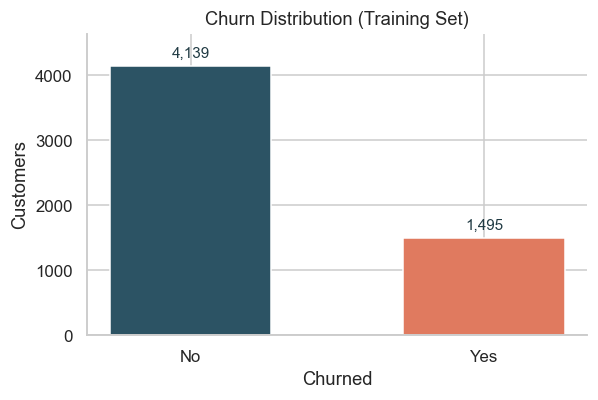

In [21]:
churn_counts = train_df["ChurnLabel"].value_counts().reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(5.6, 3.8))
colors = ["#2c5364", "#e07a5f"]
bars = ax.bar(churn_counts.index, churn_counts.values, color=colors, width=0.55)
ax.set_ylabel("Customers")
ax.set_xlabel("Churned")
ax.set_title("Churn Distribution (Training Set)")
ymax = churn_counts.max() * 1.12
ax.set_ylim(0, ymax)
for bar, val in zip(bars, churn_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2, val + ymax * 0.02, f"{val:,}",
        ha="center", va="bottom", fontsize=10, color="#203a43",
    )
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Outcome | Customers | Share of training set |
|---------|----------:|----------------------:|
| No (stayed) | **4,139** | **73.5%** |
| Yes (churned) | **1,495** | **26.5%** |
| Total | **5,634** | 100% |

The training set is **4,139** stayers vs **1,495** leavers — about **2.8:1**, or **26.5%** churn. That is the same base rate Section 1 used, and the stratified split kept the test set at 26.5% too, so later capture and ROI figures are not an artifact of a shifted mix.

A model that predicts “No” for every row is already **73.5%** accurate and catches **zero** churners. That is why accuracy is the wrong score here, and why Section 4 reports PR-AUC, recall, and top-20% capture instead. The imbalance is real but not extreme: not a case for SMOTE. It *is* enough that an unweighted loss would drift toward the navy bar. `class_weight="balanced"` and XGBoost’s `scale_pos_weight` ≈ **2.77** (exactly 4,139 / 1,495) reweight the **1,495** leavers without faking extra rows, which keeps calibration honest for the threshold in Section 4.3.

This chart is the *average* risk in the training base. It is not who churns. Tenure, contract, and charges in the plots below slice the orange bar apart.

**What follows and why it matters.** The 26.5% above is an average. Tenure is the first slice: if churn piles up among new accounts, a retention team should spend early, and `TenureBucket` belongs in the model as a clean “first year” split rather than making the tree rediscover month 12 from raw tenure.

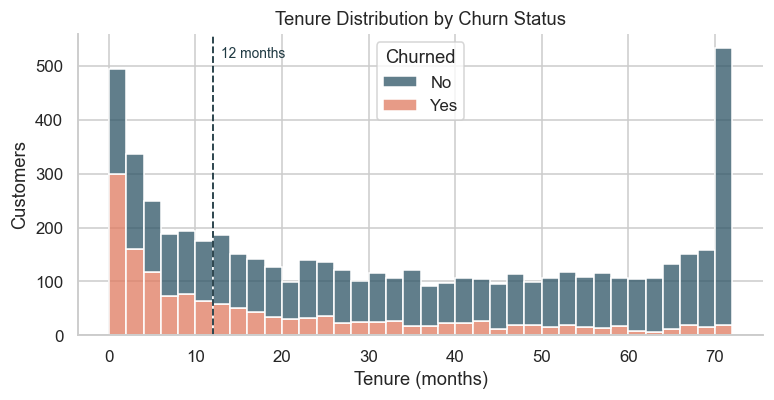

In [24]:
from IPython.display import HTML, display

medians = train_df.groupby("ChurnLabel")["tenure"].median()
n_churn = int((train_df["ChurnLabel"] == "Yes").sum())
n_churn_yr1 = int(((train_df["ChurnLabel"] == "Yes") & (train_df["tenure"] <= 12)).sum())
yr1_share = n_churn_yr1 / n_churn

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Median tenure, stayers</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{medians['No']:.0f} mo</div>
    <div style="font-size:12px; color:#5b6b73;">n = 4,139</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Median tenure, leavers</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{medians['Yes']:.0f} mo</div>
    <div style="font-size:12px; color:#5b6b73;">n = 1,495</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Leavers in first 12 months</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{yr1_share*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{n_churn_yr1:,} of {n_churn:,} churners</div>
  </div>
</div>
"""))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
sns.histplot(
    data=train_df, x="tenure", hue="ChurnLabel", hue_order=["No", "Yes"],
    multiple="stack", palette={"No": "#2c5364", "Yes": "#e07a5f"},
    bins=36, ax=ax,
)
ax.axvline(12, color="#203a43", linestyle="--", linewidth=1.2)
ax.text(13, ax.get_ylim()[1] * 0.92, "12 months", color="#203a43", fontsize=9)
ax.set_title("Tenure Distribution by Churn Status")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Customers")
ax.get_legend().set_title("Churned")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Group | Median tenure | Reading |
|-------|--------------:|---------|
| Stayers (n = 4,139) | **38 months** | Already past the dangerous year |
| Leavers (n = 1,495) | **10 months** | Still inside it |
| Leavers with tenure ≤ 12 | **822 / 1,495 = 55%** | Left of the dashed line |

Leavers leave early. Median tenure is **10 months** among the 1,495 who churned vs **38 months** among those who stayed. **55%** of all training-set churners sit at or before month 12 — left of the dashed line — while the far-right spike is almost all navy: people who made it to ~70 months and stayed.

That is a snapshot, not a survival curve. High-tenure bars are customers who already chose not to leave; the chart does not prove that “waiting 38 months” would have saved the 10-month leavers. It does show where the orange mass is: the first year, when switching costs (term contract, add-ons, habit) are still thin.

`TenureBucket` is the explicit cut this plot argues for (0–1 year vs later). Raw `tenure` stays in the model too, so the tree can still split 1 vs 11 months inside that first year. The next chart asks whether “early” is really tenure, or mostly month-to-month contracts that happen to be new.

**What follows and why it matters.** The tenure plot showed *when* people leave. Contract type is *how easy* it is to leave in any given month. These are training-set **rates**, not headcount: a 43% bar on a large group is a different operational problem than a 3% bar on a smaller one. SHAP in Section 4.5 will say whether the model uses this split; this cell only asks whether the raw data already does.

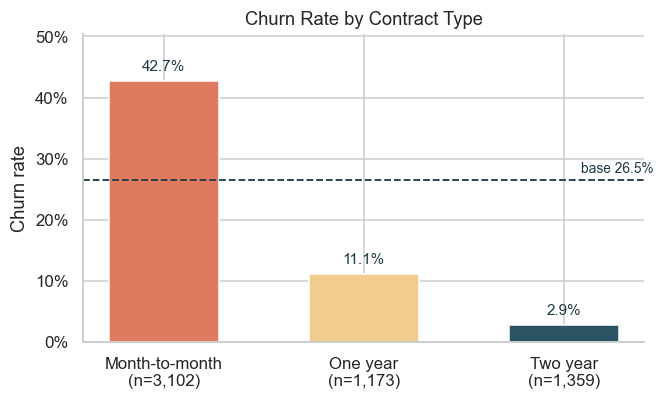

In [27]:
from IPython.display import HTML, display

base = train_df["Churn"].mean()
contract_churn = (
    train_df.groupby("Contract")
    .agg(churn_rate=("Churn", "mean"), n=("Churn", "size"), n_churn=("Churn", "sum"))
    .reset_index()
    .sort_values("churn_rate", ascending=False)
)
n_churn_total = int(train_df["Churn"].sum())

display(HTML(
    "<div style=\"display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;\">"
    + "".join(
        f"""
        <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid {color};">
          <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">{row.Contract}</div>
          <div style="font-size:22px; font-weight:600; color:#203a43;">{row.churn_rate*100:.1f}&#37;</div>
          <div style="font-size:12px; color:#5b6b73;">{int(row.n_churn):,} of {int(row.n):,} · {row.n_churn/n_churn_total*100:.0f}&#37; of all leavers</div>
        </div>
        """
        for row, color in zip(contract_churn.itertuples(), ["#e07a5f", "#f2cc8f", "#2c5364"])
    )
    + "</div>"
))

fig, ax = plt.subplots(figsize=(6.2, 3.8))
colors = ["#e07a5f", "#f2cc8f", "#2c5364"]
bars = ax.bar(contract_churn["Contract"], contract_churn["churn_rate"], color=colors, width=0.55)
ax.axhline(base, color="#203a43", linestyle="--", linewidth=1.2)
ax.text(2.45, base + 0.012, f"base {base:.1%}", ha="right", fontsize=9, color="#203a43")
ax.set_ylim(0, contract_churn["churn_rate"].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Churn rate")
ax.set_title("Churn Rate by Contract Type")
ax.set_xticks(range(len(contract_churn)))
ax.set_xticklabels(
    [f"{c}\n(n={n:,.0f})" for c, n in zip(contract_churn["Contract"], contract_churn["n"])]
)
for bar, val in zip(bars, contract_churn["churn_rate"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.012, f"{val:.1%}",
            ha="center", va="bottom", fontsize=10, color="#203a43")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Contract | Churn rate | Accounts | Share of all 1,495 leavers |
|----------|----------:|---------:|---------------------------:|
| Month-to-month | **42.7%** | 3,102 | **89%** (1,326) |
| One year | **11.1%** | 1,173 | 9% (130) |
| Two year | **2.9%** | 1,359 | 3% (39) |

Month-to-month churn is **42.7%** - **1.6×** the 26.5% training base, and about **15×** the two-year rate (**2.9%**). One-year sits in between at **11.1%**. The dashed line is that 26.5% average: two contract types sit well below it; one sits well above.

The operational cut is sharper than the rates. Month-to-month is **55%** of the training base and **89%** of the people who actually left. A retention list that ignored contract would still spend most of its time in that orange bar.

This is association, not a proof that converting everyone to two-year would cut churn to 3%. Month-to-month customers are also newer (the last plot). SHAP has to separate the contract dummy from tenure and charges. What you can say now: lock-in is the largest raw split in the data, and it is the lever Section 5.5 tests first.

**What follows and why it matters.** Tenure and contract said *when* and *how easy* it is to leave. Monthly charges are *what they pay*. If leavers sit higher on the bill, the model has a price-value signal - but only if the boxes actually separate. A small median gap with a huge overlap is a weak standalone lever; it is more useful later as `ChargeRatio` (bill vs history) than as a raw dollar cutoff.

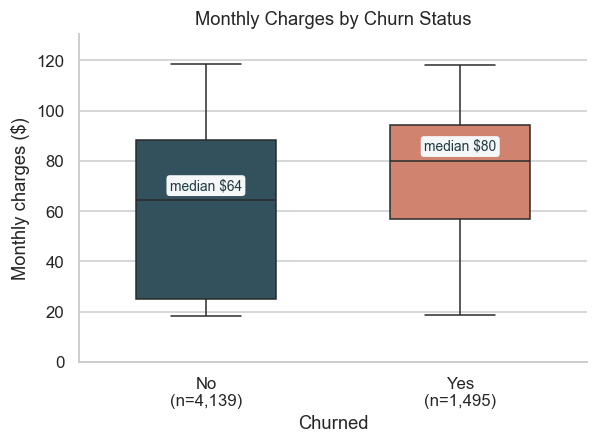

In [30]:
from IPython.display import HTML, display

medians = train_df.groupby("ChurnLabel")["MonthlyCharges"].median()
means = train_df.groupby("ChurnLabel")["MonthlyCharges"].mean()
counts = train_df["ChurnLabel"].value_counts()
delta = medians["Yes"] - medians["No"]

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Median bill, stayers</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">&#36;{medians['No']:.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">n = {counts['No']:,} · mean &#36;{means['No']:.0f}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Median bill, leavers</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">&#36;{medians['Yes']:.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">n = {counts['Yes']:,} · mean &#36;{means['Yes']:.0f}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Median gap</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">+&#36;{delta:.0f}/mo</div>
    <div style="font-size:12px; color:#5b6b73;">leavers vs stayers</div>
  </div>
</div>
"""))

fig, ax = plt.subplots(figsize=(5.6, 4.2))
sns.boxplot(
    data=train_df, x="ChurnLabel", y="MonthlyCharges",
    hue="ChurnLabel", hue_order=["No", "Yes"],
    palette={"No": "#2c5364", "Yes": "#e07a5f"},
    width=0.55, legend=False, ax=ax,
)
ax.set_xticks([0, 1])
ax.set_xticklabels([f"No\n(n={counts['No']:,})", f"Yes\n(n={counts['Yes']:,})"])
for i, label in enumerate(["No", "Yes"]):
    ax.text(
        i, medians[label] + 3, f"median ${medians[label]:.0f}",
        ha="center", va="bottom", fontsize=9, color="#203a43",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="#f4f6f7", edgecolor="none"),
    )
ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churned")
ax.set_ylabel("Monthly charges ($)")
ax.set_ylim(0, train_df["MonthlyCharges"].max() * 1.10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Group | Median bill | Mean bill | n |
|-------|------------:|----------:|--:|
| Stayers | **\$64** | \$61 | 4,139 |
| Leavers | **\$80** | \$75 | 1,495 |
| Gap | **+\$16 per month** | +\$14 per month | |

Leavers pay more: median **\$80** vs **\$64**, about **\$16 per month**. The means agree (**\$75** vs **\$61**). The boxes still overlap almost entirely - stayers span roughly \$25–\$88, leavers \$57–\$94, and both reach about \$118 - so a flat "high bill" cutoff would flag a large number of people who stay. The visible difference is the floor: the orange box starts much higher. Leavers rarely sit in the cheap tier at all.

Those extra dollars are not a pure price effect. **70%** of leavers are on fiber (median fiber bill about \$92) vs **35%** of stayers, and no-internet accounts sit near **\$20** and almost never churn. Contract and tenure are inside this plot too: month-to-month fiber is both expensive and easy to leave.

So monthly charge is a real shift in level, not a separator on its own. That is why the engineered feature is `ChargeRatio` - the bill relative to accumulated billing history - and why SHAP later ranks it above raw `MonthlyCharges`. Do not read "charge them less" off this box plot.

**What follows and why it matters.** Before modeling, check whether any two numeric features are so aligned that they are the same story twice. That does not break a tree model the way it breaks linear regression, but it *does* split SHAP credit across both names. The question is which pairs are mechanical (bill × time, bill × add-ons) and whether `ChargeRatio` is actually new information.

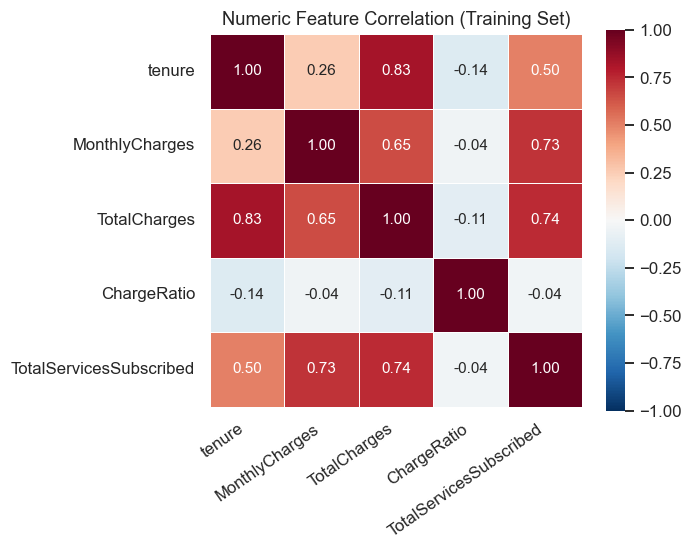

In [33]:
corr = train_df[numeric_features].corr()

fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.6,
    annot_kws={"size": 10}, ax=ax,
)
ax.set_title("Numeric Feature Correlation (Training Set)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

| Pair | r | What it is |
|------|--:|------------|
| `tenure` × `TotalCharges` | **0.83** | Running bill ≈ rate × time |
| `TotalServicesSubscribed` × `TotalCharges` | **0.74** | More add-ons, larger lifetime bill |
| `MonthlyCharges` × `TotalServicesSubscribed` | **0.73** | Each add-on raises the monthly price |
| `MonthlyCharges` × `TotalCharges` | **0.65** | Higher rate accumulates faster |
| `ChargeRatio` × `MonthlyCharges` | **−0.04** | Almost no linear overlap with the raw bill |

The strongest pair is mechanical: **`tenure` and `TotalCharges` at 0.83**. Stay longer, pay more in total. Services vs monthly bill (**0.73**) is the same kind of identity - add-ons are priced in. Neither pair is leakage, and neither is a reason to drop a column from XGBoost. Trees can split on both. SHAP may *share* importance between `tenure` and `TotalCharges`, so do not over-read a close ranking between those two later.

`ChargeRatio` is the feature this matrix is meant to justify. It is almost uncorrelated with `MonthlyCharges` (**−0.04**) and only weakly related to tenure (**−0.14**). The box plot’s “leavers pay 16 dollars more” is a level shift; `ChargeRatio` is bill vs history - a different axis, which is why it can outrank raw charges in Section 4.5.

All five numeric features stay. The high-r pairs are not 1.0, and this model class does not need orthogonal inputs.

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="4-modeling"></a>
## 4. Modeling

This section trains three candidate models on the identical preprocessing pipeline, tunes the strongest candidate with Optuna, chooses a deliberate decision threshold, checks whether its probabilities are trustworthy on their own terms (calibration), and then explains its predictions with SHAP.

<a id="41-baseline-model-comparison"></a>
### 4.1 Baseline Model Comparison

**What follows and why it matters.** Three estimators, one preprocessor, one imbalance recipe. Logistic Regression is the linear baseline, Random Forest the bagged tree, XGBoost the boosted tree (and the intended champion because TreeSHAP is native). The ranking metric is **PR-AUC** — Section 1 already dropped accuracy. Recall, precision, and F1 in this table are at the **default 0.5 cutoff**, not the 0.59 flag from Section 4.3. This cell only asks which family ranks leavers best *before* anyone is tuned.

Model,ROC-AUC,PR-AUC,Recall,Precision,F1
Logistic Regression,0.8422,0.6353,0.7914,0.4983,0.6116
Random Forest,0.8261,0.6213,0.4840,0.6241,0.5452
XGBoost,0.8106,0.6017,0.5909,0.5351,0.5616


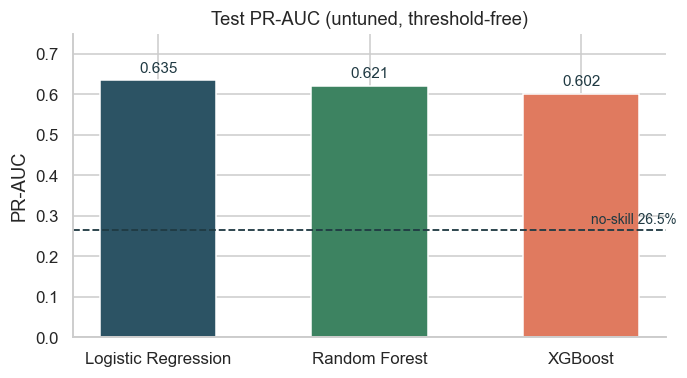

In [38]:
baseline_models = get_baseline_models(preprocessor, scale_pos_weight)
comparison_table, fitted_models = compare_models(baseline_models, X_train, y_train, X_test, y_test)

display(comparison_table.style.background_gradient(
    subset=["PR-AUC", "ROC-AUC"], cmap="Greens"
).format(precision=4).hide(axis="index"))

no_skill = float(y_test.mean())
prauc = comparison_table.set_index("Model")["PR-AUC"]
colors = {
    "Logistic Regression": "#2c5364",
    "Random Forest": "#3d8361",
    "XGBoost": "#e07a5f",
}

fig, ax = plt.subplots(figsize=(6.4, 3.6))
bars = ax.bar(prauc.index, prauc.values, color=[colors[m] for m in prauc.index], width=0.55)
ax.axhline(no_skill, color="#203a43", linestyle="--", linewidth=1.2)
ax.text(2.45, no_skill + 0.015, f"no-skill {no_skill:.1%}", ha="right", fontsize=9, color="#203a43")
ax.set_ylim(0, max(prauc.max() * 1.18, no_skill * 1.3))
ax.set_ylabel("PR-AUC")
ax.set_title("Test PR-AUC (untuned, threshold-free)")
for bar, val in zip(bars, prauc.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.012, f"{val:.3f}",
            ha="center", va="bottom", fontsize=10, color="#203a43")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Model | PR-AUC | ROC-AUC | Recall @ 0.5 | Precision @ 0.5 | F1 @ 0.5 |
|-------|-------:|--------:|-------------:|----------------:|---------:|
| Logistic Regression | **0.635** | **0.842** | **0.791** | 0.498 | **0.612** |
| Random Forest | 0.621 | 0.826 | 0.484 | **0.624** | 0.545 |
| XGBoost (untuned) | 0.602 | 0.811 | 0.591 | 0.535 | 0.562 |

The dashed line is no-skill PR-AUC: the **26.5%** base rate. All three bars clear it. **Logistic Regression is first** on both ranking scores (**0.635** PR-AUC, **0.842** ROC-AUC) and catches the most leavers at the default 0.5 cutoff (**79% recall**, ~50% precision). Random Forest is the conservative one: fewest catches, highest precision. Untuned XGBoost is last (**0.602**).

Recall and precision in that table are **not** the campaign metrics. They are the default 0.5 cutoff. Section 4.3 picks the flag; Section 5.2 picks the call list.

XGBoost is still the champion *candidate* - TreeSHAP is native (4.5), and default trees are under-regularized. Section 4.2 has to close the **0.033** PR-AUC gap. If it does not, logistic regression is the more honest model to ship. This ranking is one 80/20 split (`random_state=42`), same preprocessor and weighting for every row, not a CV bake-off of the three families.

<a id="42-hyperparameter-tuning-with-optuna"></a>
### 4.2 Hyperparameter Tuning with Optuna

**What follows and why it matters.** Untuned XGBoost lost Section 4.1 on PR-AUC (**0.602** vs logistic **0.635**). This cell searches XGBoost hyperparameters with Optuna (TPE), scoring each trial by **4-fold CV PR-AUC on the training set only** — the test set is not in the loop. PR-AUC, not ROC-AUC, because the minority class is what Section 5 spends money on. The orange line is the best score seen so far; if it flattens, more trials are unlikely to change the pick.

In [41]:
N_OPTUNA_TRIALS = 30
study = tune_xgboost_optuna(
    X_train, y_train, preprocessor, scale_pos_weight,
    n_trials=N_OPTUNA_TRIALS, cv_folds=4,
)

print(f"Best cross-validated PR-AUC: {study.best_value:.4f}")
print("Best hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best cross-validated PR-AUC: 0.6735
Best hyperparameters:
  n_estimators: 450
  max_depth: 4
  learning_rate: 0.05864129169696527
  subsample: 0.7733551396716398
  colsample_bytree: 0.5924272277627636
  min_child_weight: 10
  gamma: 3.8756641168055728
  reg_alpha: 5.727904470799623
  reg_lambda: 3.7958531426706403


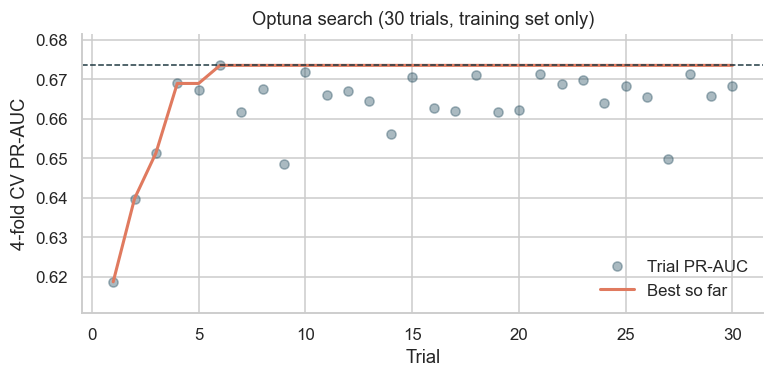

In [42]:
from IPython.display import HTML, display

trial_values = [t.value for t in study.trials if t.value is not None]
running_best = np.maximum.accumulate(trial_values)
best_trial = int(np.argmax(trial_values)) + 1
p = study.best_params

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Best CV PR-AUC</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{study.best_value:.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">trial {best_trial} of {N_OPTUNA_TRIALS} · train folds only</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Tree size</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">depth {p['max_depth']}</div>
    <div style="font-size:12px; color:#5b6b73;">{p['n_estimators']} trees · min_child_weight {p['min_child_weight']}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Regularization</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">gamma {p['gamma']:.1f}</div>
    <div style="font-size:12px; color:#5b6b73;">alpha {p['reg_alpha']:.1f} · lambda {p['reg_lambda']:.1f}</div>
  </div>
</div>
"""))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
x = np.arange(1, len(trial_values) + 1)
ax.plot(x, trial_values, "o", alpha=0.4, color="#2c5364", label="Trial PR-AUC")
ax.plot(x, running_best, "-", linewidth=2, color="#e07a5f", label="Best so far")
ax.axhline(study.best_value, color="#203a43", linestyle="--", linewidth=1.0)
ax.set_xlabel("Trial")
ax.set_ylabel("4-fold CV PR-AUC")
ax.set_title(f"Optuna search ({N_OPTUNA_TRIALS} trials, training set only)")
ax.set_ylim(min(trial_values) - 0.008, max(trial_values) + 0.008)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| | Value | What it is |
|--|------:|------------|
| Best **CV** PR-AUC | **0.674** (trial 6 of 30) | 4-fold on the 5,634 training rows |
| Untuned XGBoost **test** PR-AUC | 0.602 | Section 4.1 — different cut of the data |
| Next cell | test PR-AUC after refit | The number that has to beat logistic **0.635** |

Optuna did not grow a giant forest. It picked a **shallow** tree (**max_depth = 4**), **450** estimators, **min_child_weight = 10**, and heavy **gamma / L1 / L2** (3.9 / 5.7 / 3.8). That is a regularizer on ~5,600 rows, not a complexity contest.

The orange “best so far” line jumps through trial 6, then sits on the dashed **0.674** line. The remaining 24 dots jitter below it. Thirty trials were enough; more search would almost certainly not change the pick.

Do not read 0.674 as the test-set win. CV is the training folds talking to themselves. The next cell refits `champion_pipeline` on the full training set and scores the 1,409 held-out rows. That is where we check whether tuning closed the 4.1 gap.

**Refit and holdout check.** Optuna’s 0.674 was cross-validation on the training folds. This cell locks those hyperparameters, fits once on all 5,634 training rows, and scores the 1,409 test customers. That test PR-AUC is the number that has to beat logistic regression’s **0.635**.

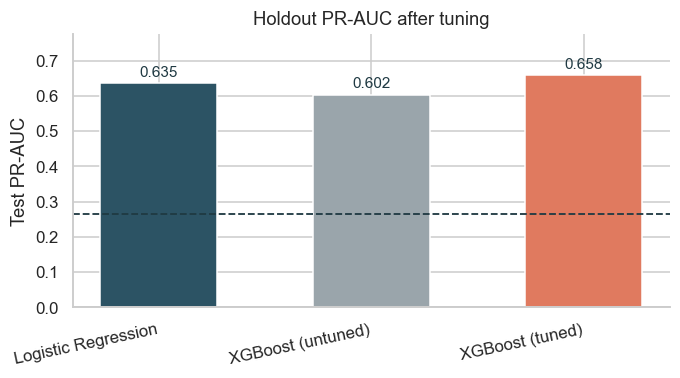

In [45]:
from IPython.display import HTML, display
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

champion_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        **study.best_params,
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1,
    )),
])
champion_pipeline.fit(X_train, y_train)

tuned_metrics = evaluate_model(champion_pipeline, X_test, y_test)
lr_prauc = float(comparison_table.loc[
    comparison_table["Model"] == "Logistic Regression", "PR-AUC"
].iloc[0])
xgb_base = float(comparison_table.loc[
    comparison_table["Model"] == "XGBoost", "PR-AUC"
].iloc[0])
tuned_prauc = tuned_metrics["PR-AUC"]

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Tuned test PR-AUC</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{tuned_prauc:.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">held-out 1,409 · threshold-free</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">vs logistic</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{tuned_prauc-lr_prauc:+.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">logistic was {lr_prauc:.3f}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">vs untuned XGBoost</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{tuned_prauc-xgb_base:+.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">untuned was {xgb_base:.3f}</div>
  </div>
</div>
"""))

compare = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost (untuned)", "XGBoost (tuned)"],
    "PR-AUC": [lr_prauc, xgb_base, tuned_prauc],
})
colors = ["#2c5364", "#9aa5ab", "#e07a5f"]

fig, ax = plt.subplots(figsize=(6.4, 3.6))
bars = ax.bar(compare["Model"], compare["PR-AUC"], color=colors, width=0.55)
ax.axhline(float(y_test.mean()), color="#203a43", linestyle="--", linewidth=1.2)
ax.set_ylim(0, compare["PR-AUC"].max() * 1.18)
ax.set_ylabel("Test PR-AUC")
ax.set_title("Holdout PR-AUC after tuning")
for bar, val in zip(bars, compare["PR-AUC"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.012, f"{val:.3f}",
            ha="center", va="bottom", fontsize=10, color="#203a43")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()

| Model | Test PR-AUC | vs no-skill (0.265) |
|-------|------------:|--------------------:|
| Logistic Regression | 0.635 | +0.370 |
| XGBoost (untuned) | 0.602 | +0.337 |
| **XGBoost (tuned)** | **0.658** | **+0.393** |

Tuning did the job Section 4.1 asked for. Holdout PR-AUC moves from **0.602** to **0.658** (**+0.056**), and it now **beats logistic by +0.022**. The dashed line is still the 26.5% base rate; all three clear it. The gray bar is why you do not ship default XGBoost.

Test **0.658** sits under the CV peak **0.674**. That gap is the price of a real holdout, not a failure of the search.

Recall / precision at 0.5 (about **80% / 51%**) are still not the campaign rule. Section 4.3 picks the flag; Section 5.2 uses the ranking. `champion_pipeline` is now the model every later cell scores, explains, and prices - and carrying it is no longer a SHAP-only preference.

<a id="43-threshold-optimization"></a>
### 4.3 Threshold Optimization

**What follows and why it matters.** A classifier's default 0.5 cutoff is arbitrary — it is not derived from anything about this problem's costs. The chart below sweeps every threshold from 0.05 to 0.95 and plots precision, recall, and F1 at each one. The peak-F1 cutoff becomes the High / Low flag used to size exposure in Section 5.3. It is not the call list: Section 5.2 ranks people and takes the top 20%.

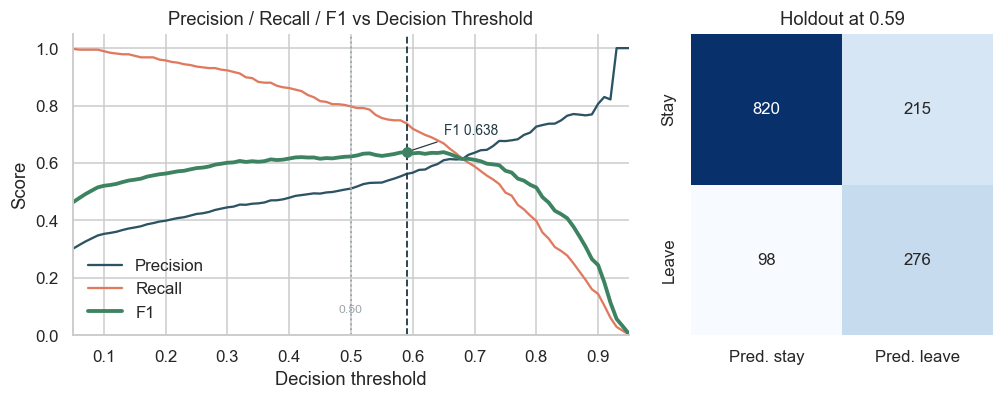

In [48]:
from IPython.display import HTML, display
from sklearn.metrics import confusion_matrix

y_proba_test = champion_pipeline.predict_proba(X_test)[:, 1]
best_threshold, threshold_sweep = optimize_threshold(y_test, y_proba_test)

metrics_at_best = evaluate_model(champion_pipeline, X_test, y_test, threshold=best_threshold)
metrics_at_half = evaluate_model(champion_pipeline, X_test, y_test, threshold=0.50)

y_pred = (y_proba_test >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
n_flagged = int(tp + fp)
n_test = int(len(y_test))
n_churn = int(y_test.sum())
best_row = threshold_sweep.loc[threshold_sweep["f1"].idxmax()]

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Chosen threshold</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{best_threshold:.2f}</div>
    <div style="font-size:12px; color:#5b6b73;">F1-max · default is 0.50</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Precision</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{metrics_at_best['Precision']*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{(metrics_at_best['Precision']-metrics_at_half['Precision'])*100:+.1f} pp vs 0.50</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Recall</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{metrics_at_best['Recall']*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{(metrics_at_best['Recall']-metrics_at_half['Recall'])*100:+.1f} pp vs 0.50</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9c27b0;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Flagged</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{n_flagged:,}</div>
    <div style="font-size:12px; color:#5b6b73;">{n_flagged/n_test*100:.1f}&#37; of {n_test:,} · F1 {metrics_at_best['F1']:.3f}</div>
  </div>
</div>
"""))

fig, (ax, ax_cm) = plt.subplots(
    1, 2, figsize=(9.4, 3.8), gridspec_kw={"width_ratios": [1.7, 1]}
)

ax.plot(threshold_sweep["threshold"], threshold_sweep["precision"],
        label="Precision", color="#2c5364")
ax.plot(threshold_sweep["threshold"], threshold_sweep["recall"],
        label="Recall", color="#e07a5f")
ax.plot(threshold_sweep["threshold"], threshold_sweep["f1"],
        label="F1", color="#3d8361", linewidth=2.5)
ax.axvline(0.50, color="#9aa5ab", linestyle=":", linewidth=1.2)
ax.axvline(best_threshold, color="#203a43", linestyle="--", linewidth=1.2)
ax.plot(best_row["threshold"], best_row["f1"], "o", color="#3d8361", zorder=5)
ax.annotate(
    f"F1 {best_row['f1']:.3f}",
    xy=(best_row["threshold"], best_row["f1"]),
    xytext=(best_row["threshold"] + 0.06, best_row["f1"] + 0.06),
    color="#203a43", fontsize=9,
    arrowprops=dict(arrowstyle="-", color="#203a43", lw=0.8),
)
ax.text(0.50, 0.08, "0.50", ha="center", fontsize=8, color="#9aa5ab")
ax.set_xlim(0.05, 0.95)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs Decision Threshold")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)

sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues", cbar=False, square=True,
    xticklabels=["Pred. stay", "Pred. leave"],
    yticklabels=["Stay", "Leave"],
    annot_kws={"size": 11}, ax=ax_cm,
)
ax_cm.set_title(f"Holdout at {best_threshold:.2f}")
ax_cm.set_xlabel("")
ax_cm.set_ylabel("")

plt.tight_layout()
plt.show()

| Cutoff | Flagged | Precision | Recall | F1 | What it is |
|--------|--------:|----------:|-------:|---:|------------|
| Default 0.50 | more contacts | 51.1% | 79.7% | 0.623 | Arbitrary |
| **F1-max 0.59** | **491** of 1,409 | **56.2%** | **73.8%** | **0.638** | The High / Low flag |

Raising the bar from the dotted 0.50 line to **0.59** buys **+5.1 pp** precision and costs **−5.9 pp** recall. F1 only moves **0.623 → 0.638**. The green curve is already flat around that peak - a nearby cutoff would look almost the same on F1 and different on headcount. The matrix is the headcount: **276** true leavers caught, **215** false alarms, **98** missed, **820** correctly left alone. So **276 of 374** leavers sit behind the flag (**73.8%**), inside **491** people (**34.8%** of the test set).

Do not read 0.59 as a cost-optimal rule. F1 treats a false alarm and a missed leaver as equal. Under the Section 5.4 assumptions they are not: a wasted contact is \$50; a missed leaver is a year of bill. A cost-weighted cutoff would sit *lower* and flag more people. 0.59 is therefore a **conservative proxy**, not a budget.

Keep the two Section 5 uses separate. This flag marks exposure - the **491** accounts and the **\$441,250** in 5.3. The call list in 5.2 is a ranking: **282** people, **190** true leavers. Staff to the list. Use 0.59 to say who is High.

PR-AUC is still **0.658**. It does not move with the cutoff; the sweep only carves a yes/no out of the same ranking. Section 4.4 checks whether those scores can be read as probabilities before 5.3 multiplies the flag into dollars.

<a id="44-probability-calibration"></a>
### 4.4 Probability Calibration

**What follows and why it matters.** Ranking still works if the scores are only ordered correctly - that is all Section 5.2 uses. Reading 0.59 as “about a 59% chance,” and trusting the percentage-point drops in the Section 5.5 what-if, do not. The diagram bins the 1,409 holdout scores into ten equal-sized groups and plots mean predicted probability against the actual churn rate in that group. A perfectly calibrated model sits on the diagonal.

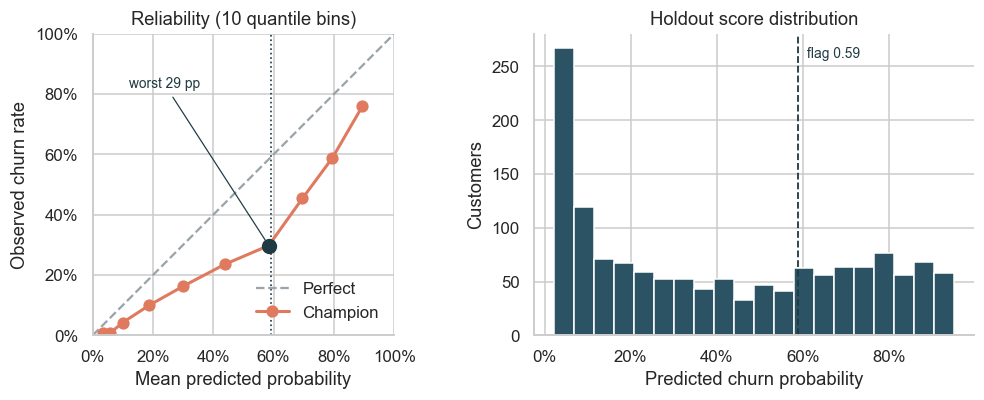

In [51]:
from IPython.display import HTML, display
from sklearn.metrics import brier_score_loss

frac_positive, mean_predicted = get_calibration_curve(y_test, y_proba_test, n_bins=10)

abs_gap = np.abs(frac_positive - mean_predicted)
ece = float(abs_gap.mean())
max_gap = float(abs_gap.max())
worst_i = int(np.argmax(abs_gap))
brier = float(brier_score_loss(y_test, y_proba_test))
mean_pred = float(np.asarray(y_proba_test).mean())
obs_rate = float(np.asarray(y_test).mean())
brier_ref = obs_rate * (1 - obs_rate)
n_bin = int(np.round(len(y_test) / 10))

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Brier score</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{brier:.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">no-skill (always {obs_rate:.1%}) is {brier_ref:.3f}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Worst-bin gap</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{max_gap*100:.1f} pp</div>
    <div style="font-size:12px; color:#5b6b73;">pred {mean_predicted[worst_i]:.0%} · obs {frac_positive[worst_i]:.0%}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Mean predicted</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{mean_pred*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">observed base rate {obs_rate*100:.1f}&#37;</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9c27b0;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Mean abs. error</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{ece*100:.1f} pp</div>
    <div style="font-size:12px; color:#5b6b73;">10 quantile bins · ~{n_bin} each</div>
  </div>
</div>
"""))

fig, (ax, ax_h) = plt.subplots(
    1, 2, figsize=(9.4, 3.8), gridspec_kw={"width_ratios": [1, 1.15]}
)

ax.plot([0, 1], [0, 1], linestyle="--", color="#9aa5ab", label="Perfect")
ax.plot(mean_predicted, frac_positive, "o-", color="#e07a5f",
        linewidth=2, markersize=7, label="Champion")
ax.plot(mean_predicted[worst_i], frac_positive[worst_i], "o",
        color="#203a43", markersize=9, zorder=5)
ax.annotate(
    f"worst {max_gap*100:.0f} pp",
    xy=(mean_predicted[worst_i], frac_positive[worst_i]),
    xytext=(0.12, 0.82),
    color="#203a43", fontsize=9,
    arrowprops=dict(arrowstyle="-", color="#203a43", lw=0.8),
)
ax.axvline(best_threshold, color="#203a43", linestyle=":", linewidth=1.1)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Reliability (10 quantile bins)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

ax_h.hist(y_proba_test, bins=20, color="#2c5364", edgecolor="white")
ax_h.axvline(best_threshold, color="#203a43", linestyle="--", linewidth=1.2)
ax_h.text(best_threshold + 0.02, ax_h.get_ylim()[1] * 0.92,
          f"flag {best_threshold:.2f}", color="#203a43", fontsize=9)
ax_h.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax_h.set_xlabel("Predicted churn probability")
ax_h.set_ylabel("Customers")
ax_h.set_title("Holdout score distribution")
ax_h.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

| Check | Number | What it is |
|-------|-------:|------------|
| Brier | **0.162** | Beats a dummy that always says 26.5% (**0.195**). The ranking has information. |
| Mean predicted | **40.8%** vs **26.5%** observed | Systematic over-call. `scale_pos_weight` ≈ 2.77 shifted the whole scoreboard up. |
| Worst-bin gap | **28.6 pp** | Pred **58%** · obs **30%** — the bin that sits on the 0.59 flag |
| Mean \|error\| | **14.3 pp** | Same size as the overall bias. This is a *shift*, not noise around the diagonal. |

Orange sits under the dashed line from about 20% to 80%. A score of 0.70 is not a 70% chance. The worst black dot is the one that matters for the flag: people the model scores around **0.58** leave at **30%**, barely above the base rate. That is why you should not say “0.59 means 59%.”

Two uses stay intact. Section 5.2 only needs the *order* — the histogram still piles stayers at the left and the 5.1 staircase still holds (top decile observed **75.9%**). Section 5.3 flags at 0.59 and sums *actual* bills; it never multiplies by *p*. The **56.2%** precision on the 491-person flag is a mix of that soft middle and the hard tail, not a calibration number.

Two uses do not. Do not read 0.59 out loud as a probability. And the Section 5.5 drops (**95.1% → 81.5% → 69.3%**) are movements on an *inflated* scale — direction is usable, the levels are high. If you later price an account as *p* × bill × 12, apply Platt or isotonic first. Until that use case exists, do not retune the champion to chase the diagonal. Section 4.5 asks a different question of the same scores: *why* this person is High.

<a id="45-model-interpretability-with-shap"></a>
### 4.5 Model Interpretability with SHAP

**What follows and why it matters.** A ranked list is only actionable if the retention team knows *why* this person is High. SHAP attributes each prediction to individual features in a way that is both locally exact (one customer) and globally aggregable (all 1,409 test rows) — which is why it is used here instead of raw XGBoost feature importance. The plots explain *this* champion's scores, including the over-call Section 4.4 already measured. They are not a causal treatment effect.

In [54]:
from IPython.display import HTML, display

explainer, X_test_transformed, transformed_feature_names = build_explainer(
    champion_pipeline, X_test
)
shap_values = compute_shap_values(explainer, X_test_transformed)
verification = verify_additivity(
    explainer,
    shap_values,
    champion_pipeline.named_steps["classifier"],
    X_test_transformed,
)
pretty_names = [
    n.replace("categorical__", "").replace("numeric__", "")
    for n in transformed_feature_names
]

n_rows, n_cols = shap_values.shape
base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">SHAP matrix</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{n_rows:,} × {n_cols}</div>
    <div style="font-size:12px; color:#5b6b73;">customers × transformed features</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Max |margin gap|</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{verification['max_abs_diff']:.2e}</div>
    <div style="font-size:12px; color:#5b6b73;">{verification['n_rows_checked']:,} rows checked</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Additivity</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{"Passed" if verification["passed"] else "Failed"}</div>
    <div style="font-size:12px; color:#5b6b73;">base + Σ SHAP = raw margin</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9c27b0;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Base value</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{base_value:.3f}</div>
    <div style="font-size:12px; color:#5b6b73;">E[f(X)] on the raw margin</div>
  </div>
</div>
"""))

**Additivity verification - what this check is.** Before trusting any SHAP plot, confirm the claim: for every customer, the base rate (`expected_value`) plus that customer's SHAP contributions must sum to the model's own raw margin. If they do not, the explainer is being fed the wrong inputs (raw columns instead of the preprocessor output) and every plot downstream would be misleading.

The reconstructed and actual margins match to within floating-point noise (**2.86e-06**) across all **1,409** held-out customers. Every SHAP plot in the rest of this section is therefore a mathematically exact decomposition of *this* model's predictions, not an approximation or a separately-fit surrogate.

The units are the raw margin (log-odds), not a probability. Section 4.4 already showed those probabilities are shifted up (`scale_pos_weight` ≈ 2.77). Additivity still holds: SHAP explains the inflated scores exactly. It does not undo the over-call.

**Global importance - what follows and why it matters.** Averaging the absolute SHAP value of each feature across every test customer ranks features by how much they move predictions overall, in the units of the model's own margin. That is a more faithful ranking than a generic feature-importance score, because it accounts for both how often a feature matters and how strongly it swings the prediction when it does. The bars are unsigned: direction is in the beeswarm below.

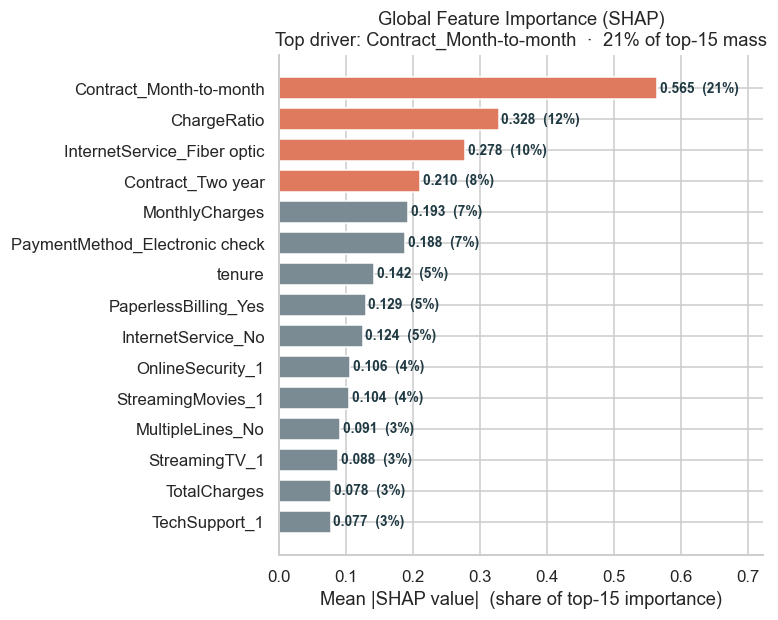

In [57]:
from IPython.display import HTML, display

top_shap_features = global_importance(shap_values, transformed_feature_names, top_n=15)
plot_df = top_shap_features.sort_values("mean_abs_shap", ascending=True).copy()
plot_df["label"] = (
    plot_df["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numeric__", "", regex=False)
)
mass = float(plot_df["mean_abs_shap"].sum())
plot_df["share"] = plot_df["mean_abs_shap"] / mass

labels = (
    top_shap_features["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numeric__", "", regex=False)
)

def _share(*needles):
    mask = False
    for needle in needles:
        mask = mask | labels.str.contains(needle, regex=False)
    return float(top_shap_features.loc[mask, "mean_abs_shap"].sum() / mass)

share_mtm = _share("Contract_Month-to-month")
share_contract = _share("Contract_Month-to-month", "Contract_Two year", "Contract_One year")
share_ratio = _share("ChargeRatio")
share_fiber = _share("Fiber optic")

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Month-to-month</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{share_mtm*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">of top-15 SHAP mass</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">All contract dummies</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{share_contract*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">month-to-month + term</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">ChargeRatio</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{share_ratio*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">bill vs billing history</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9c27b0;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Fiber optic</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{share_fiber*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">next service lever</div>
  </div>
</div>
"""))

top4 = set(top_shap_features.head(4)["feature"])
colors = ["#e07a5f" if f in top4 else "#7a8b94" for f in plot_df["feature"]]

fig, ax = plt.subplots(figsize=(7.2, 5.8))
bars = ax.barh(plot_df["label"], plot_df["mean_abs_shap"], color=colors, height=0.7)
for bar, value, share in zip(bars, plot_df["mean_abs_shap"], plot_df["share"]):
    ax.text(
        bar.get_width() + 0.004,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}  ({share:.0%})",
        va="center", ha="left", fontsize=9, color="#203a43", fontweight="bold",
    )

leader = top_shap_features.iloc[0]
leader_label = (
    str(leader["feature"])
    .replace("categorical__", "")
    .replace("numeric__", "")
)
ax.set_xlabel("Mean |SHAP value|  (share of top-15 importance)")
ax.set_title(
    "Global Feature Importance (SHAP)\n"
    f"Top driver: {leader_label}  ·  "
    f"{leader['mean_abs_shap'] / mass:.0%} of top-15 mass"
)
ax.set_xlim(0, plot_df["mean_abs_shap"].max() * 1.28)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Lever | Mean abs. SHAP | Share of top-15 mass | What it is |
|-------|---------------:|---------------------:|------------|
| Month-to-month dummy | **0.565** | **21%** | Largest single bar |
| `ChargeRatio` | **0.328** | **12%** | Bill vs accumulated history |
| Fiber optic | **0.278** | **10%** | Next service lever |
| Two-year dummy | **0.210** | **8%** | The other half of contract |
| All contract dummies | | **29%** | Month-to-month + two-year |
| Those four (orange) | | **51%** | Just over half the mass shown |

The ranking is concentrated, not a flat importance list. Contract is the first *family* (it appears twice), then price-to-history, then fiber. Mean abs. SHAP is the average *size* of each feature's push on the raw margin, not a correlation and not a probability. A large bar means the model relies on that feature when it scores customers. Sign is in the beeswarm; this chart only answers *how much*.

The gray tail is the rest of the story. Raw `MonthlyCharges` is **5th at 7%** - below the engineered `ChargeRatio`. Electronic check is tied with it (**7%**). Tenure is only **5%**. `TotalCharges` sits at the bottom (**3%**): once tenure and the monthly bill are in the model, the lifetime sum is not doing independent work. That is the Section 3 correlation matrix in SHAP units.

The business translation is unusually clean. Contract length, pricing, and service mix are levers the company can actually pull. Gender and senior-citizen status do not appear in this top 15, so they are not useful targeting rules even if they show up in a simple crosstab.

Do not read these bars as “switch everyone to two-year and churn falls 29%.” SHAP explains the champion, including the 4.4 over-call. The beeswarm adds direction. The cohort plot later will show the same dummy doing different work in different contract groups.

**Beeswarm plot - what follows and why it matters.** The bar chart ranked *how much* each feature matters. It cannot say *which way*. Each dot below is one test customer. Horizontal position is that feature's SHAP value for that customer (left = lowers predicted churn risk, right = raises it). Color is the customer's actual feature value (blue = low, red = high). A red cloud on the right means "high values of this feature raise risk."

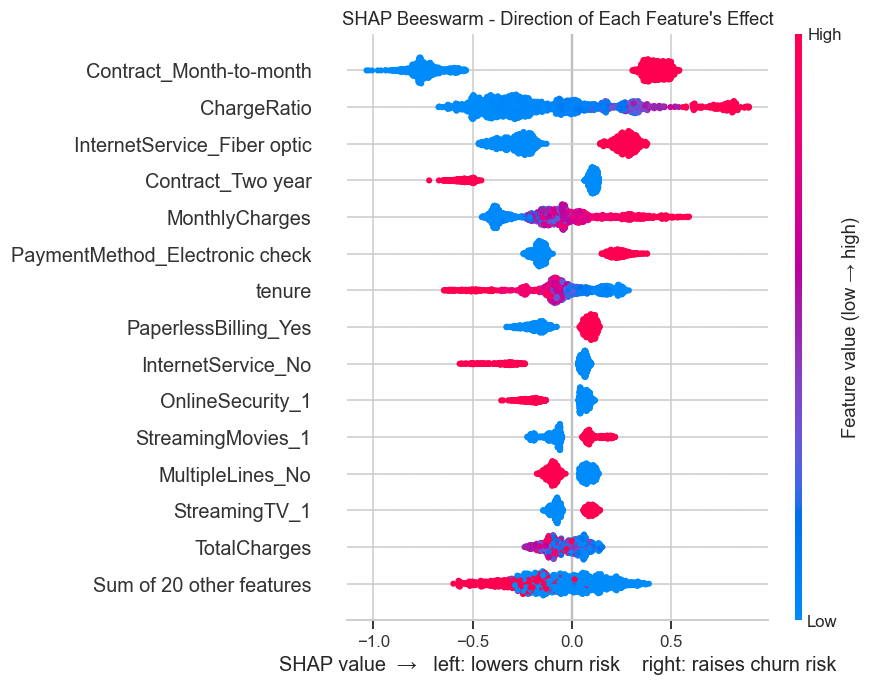

In [60]:
pretty_names = [
    n.replace("categorical__", "").replace("numeric__", "")
    for n in transformed_feature_names
]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(shap_values.shape[0], explainer.expected_value),
    data=X_test_transformed,
    feature_names=pretty_names,
)

shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False,
    plot_size=(8.2, 6.4),
    color_bar_label="Feature value (low → high)",
)
ax = plt.gcf().axes[0]
ax.set_xlabel("SHAP value  →   left: lowers churn risk    right: raises churn risk")
ax.set_title("SHAP Beeswarm - Direction of Each Feature's Effect")
plt.tight_layout()
plt.show()

**Insight:**  
Month-to-month is the clearest split on the plot. Red dots (the customer *is* month-to-month) sit around +0.4 to +0.5, raising predicted risk. Blue dots (not month-to-month) sit much farther left, around −0.8. So this is not a small nudge: being on a flexible plan raises risk, and *not* being on one is one of the strongest protective signals in the model. Two-year contracts flip that pattern - red on the left - which is lock-in, not a generic “contract matters” effect.

`ChargeRatio` has a long red tail to the right: a high bill relative to tenure pushes risk up, sometimes more than the month-to-month dummy itself. Fiber-optic service does the same in a tighter cloud. Tenure is the reverse of both. Red (long tenure) stretches left to about −0.7; blue (new customers) sits on the right. Longevity is protective; newness is a risk flag.

Electronic check, paperless billing, and streaming add-ons also put red on the right, but the clouds are smaller. Online security and having no internet sit red-on-the-left (protective). `TotalCharges` hugs zero, so the raw lifetime bill is not doing independent work once tenure and monthly price are in the model.

The risk pool is specific: new customers on month-to-month, paying a premium relative to their history, often on fiber and paying by electronic check. Those are people a contract or support offer can actually move. Demographics do not appear in this swarm, which is why they should not drive targeting.

**Local waterfall — what follows and why it matters.** The bar chart and beeswarm describe the model on average. A retention agent needs the same story for *this* person. The waterfall starts at \(E[f(X)]\) (the average model score) and adds one feature at a time until it reaches \(f(x)\) for the highest-risk test customer (predicted probability 95.1%). Red bars raise this customer's score; blue bars lower it. The length of a bar is that feature's SHAP contribution for this row only - not a global ranking.

Highest-risk test customer (row 1090)
Predicted churn probability: 95.1%
tenure                            1
Contract             Month-to-month
MonthlyCharges                 95.1
ChargeRatio                0.989594
InternetService         Fiber optic
TechSupport                       0
OnlineSecurity                    0
PaymentMethod      Electronic check


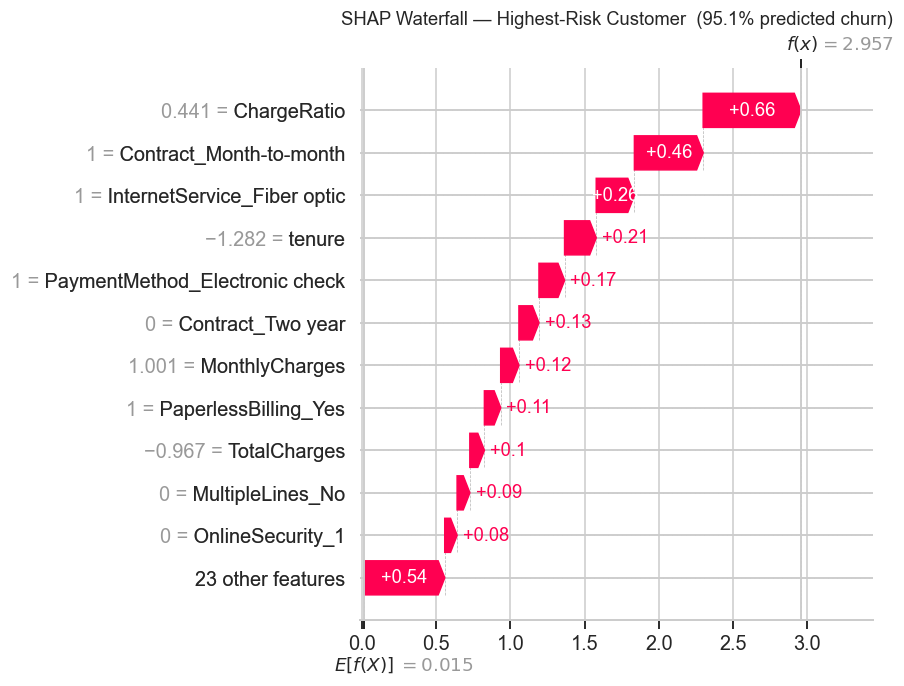

In [63]:
highest_risk_idx = int(np.argmax(y_proba_test))
customer = X_test.iloc[highest_risk_idx]
proba = float(y_proba_test[highest_risk_idx])

print(f"Highest-risk test customer (row {highest_risk_idx})")
print(f"Predicted churn probability: {proba:.1%}")
print(
    customer[
        ["tenure", "Contract", "MonthlyCharges", "ChargeRatio",
         "InternetService", "TechSupport", "OnlineSecurity", "PaymentMethod"]
    ].to_string()
)

pretty_names = [
    n.replace("categorical__", "").replace("numeric__", "")
    for n in transformed_feature_names
]
local_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(shap_values.shape[0], explainer.expected_value),
    data=X_test_transformed,
    feature_names=pretty_names,
)

shap.plots.waterfall(local_explanation[highest_risk_idx], max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(8.2, 6.4)
fig.axes[0].set_title(f"SHAP Waterfall — Highest-Risk Customer  ({proba:.1%} predicted churn)")
plt.tight_layout()
plt.show()

This customer is not a vague “high risk” flag. The model starts near the population baseline ($E[f(X)] \approx 0.02$) and climbs to $f(x) = 2.96$, which is the 95.1% churn probability. Every visible bar is red.

The two longest steps are the same levers as the global plots, in a local order: `ChargeRatio` = 0.44 adds +0.66, and a month-to-month contract adds +0.46. Fiber (+0.26), short tenure (+0.21), and electronic check (+0.17) stack on after that. Not having a two-year contract and not having online security are smaller red steps, not protections. The remaining 23 features still add +0.54 — material, but not a different story.

The call-center translation is therefore specific. The talking point is not “the model scored you 0.95.” It is “you are flagged because your bill is high relative to how long you have been a customer, you are on a month-to-month plan, and you are on fiber with electronic check.” The natural offer is a longer-term contract (and security/support if the next bars say so), which is the what-if simulation in Section 5.5.

One caution: this waterfall is *this* person. The next high-risk account can rank the same drivers in a different order — here `ChargeRatio` outruns contract, even though contract ranked first globally. That is why a local explanation belongs next to the beeswarm rather than replacing it.

Also, the numbers on the y-axis are the *transformed* values the model sees (scaled numerics, 0/1 dummies), not the original dollar amounts or months of tenure.

**Cohort comparison - what follows and why it matters.** A global ranking can hide the fact that different segments are scored for different reasons. Below, mean |SHAP| is recomputed *inside* each contract type, keeping only the top 3 drivers per group. Because |SHAP| is unsigned, a large `Contract_Month-to-month` bar in the two-year cohort means that *not* being month-to-month is doing a lot of work - the same dummy, opposite story from the beeswarm.

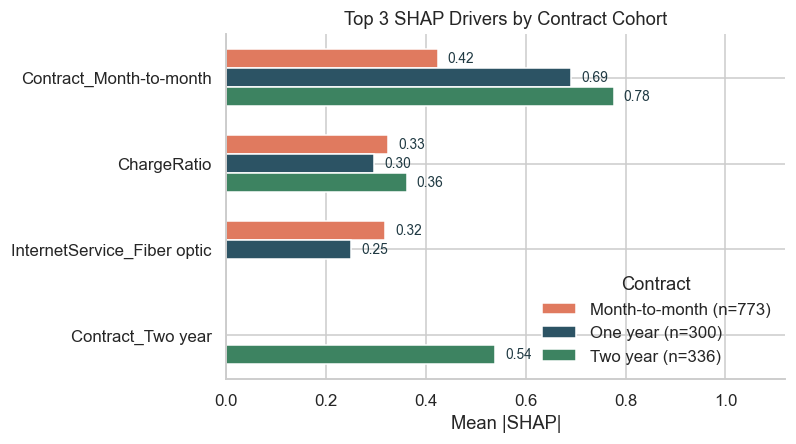

In [66]:
pretty_names = [
    n.replace("categorical__", "").replace("numeric__", "")
    for n in transformed_feature_names
]
cohort_labels = X_test["Contract"].reset_index(drop=True)
cohort_summary = cohort_shap_summary(shap_values, pretty_names, cohort_labels, top_n=3)
cohort_summary["mean_abs_shap"] = cohort_summary["mean_abs_shap"].round(3)

cohort_order = ["Month-to-month", "One year", "Two year"]
feature_order = [
    "Contract_Month-to-month",
    "ChargeRatio",
    "InternetService_Fiber optic",
    "Contract_Two year",
]
counts = cohort_labels.value_counts().reindex(cohort_order)
colors = ["#e07a5f", "#2c5364", "#3d8361"]

pivot = (
    cohort_summary
    .pivot(index="feature", columns="cohort", values="mean_abs_shap")
    .reindex(index=feature_order, columns=cohort_order)
)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
y = np.arange(len(feature_order))
bar_h = 0.22
for i, cohort in enumerate(cohort_order):
    offset = (i - 1) * bar_h
    vals = pivot[cohort].to_numpy()
    mask = ~pd.isna(vals)
    ax.barh(
        y[mask] + offset, vals[mask], height=bar_h, color=colors[i],
        label=f"{cohort} (n={counts[cohort]:,})",
    )
    for yy, vv in zip(y[mask] + offset, vals[mask]):
        ax.text(vv + 0.02, yy, f"{vv:.2f}", va="center", fontsize=9, color="#203a43")

ax.set_yticks(y)
ax.set_yticklabels(feature_order)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel("Mean |SHAP|")
ax.set_title("Top 3 SHAP Drivers by Contract Cohort")
ax.legend(title="Contract", frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The three cohorts do not share one ranking, and the unsigned |SHAP| values have to be read with the beeswarm's sign in mind.

Month-to-month customers (n = 773) are scored on a tight bundle: their own contract dummy (0.42), `ChargeRatio` (0.33), and fiber (0.32). No single bar dominates. A retention offer in this group can still pull contract length, pricing, or service mix.

One-year (n = 300) and two-year (n = 336) customers look different. `Contract_Month-to-month` jumps to 0.69 and 0.78 — *larger* than it is inside the month-to-month group. These people are not on a flexible plan; that fact is strongly protective (the beeswarm's blue cloud). Two-year customers also get 0.54 from the two-year dummy itself. Fiber drops out of their top 3. `ChargeRatio` remains, but it is no longer competing with lock-in.

So “switch them to a longer contract” only makes sense for month-to-month accounts. Longer-term customers who still look risky have already made that decision; they need a different lever (pricing, fiber experience, add-on support). Using the global #1 feature as a one-size offer would target people who are already past that point.

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="5-business-impact"></a>
## 5. Business Impact

Sections 3 and 4 answered *who is at risk* and *why the model thinks so*. This section answers *what a retention team should do with that list*.

The champion model’s test-set scores are converted into the artifacts a manager would actually use: a ranked queue (5.1), a capacity-constrained call list (5.2), a dollar exposure figure (5.3), a costed campaign (5.4), and a one-customer offer test (5.5). All of it uses the same 1,409 held-out customers scored in Section 4. Nothing is refit or re-tuned.

Two distinctions stay in force throughout. Ranking (who to call first) is not the same as a dollar threshold (who is flagged at all). And every campaign number below rests on assumptions that are stated in the cell that produces them, so they can be replaced with a real contact cost and a measured save rate.

<a id="51-risk-deciles--lift"></a>
### 5.1 Risk Deciles & Lift

**What follows and why it matters.** Rank the 1,409 test customers by predicted probability and split them into ten equal buckets (decile 1 = highest risk). A useful ranking shows a sharp downward staircase in churn rate. Lift is that rate divided by the test-set base rate (~26.5%): it answers “how much better than calling people at random is this slice?”

In [71]:
from matplotlib.ticker import PercentFormatter

base_rate = float(np.asarray(y_test).mean())
decile_table = decile_analysis(y_test, y_proba_test)
decile_table["lift"] = decile_table["churn_rate"] / base_rate

print(f"Test-set base churn rate: {base_rate:.1%}")

(
    decile_table.rename(columns={
        "decile": "Decile",
        "n_customers": "Customers",
        "n_churners": "Churners",
        "churn_rate": "Churn rate",
        "lift": "Lift vs base",
        "cumulative_churners": "Cumulative churners",
        "cumulative_capture_rate": "Cumulative capture",
    })
    .style.hide(axis="index")
    .background_gradient(subset=["Churn rate", "Cumulative capture"], cmap="Oranges")
    .format({
        "Churn rate": "{:.1%}",
        "Cumulative capture": "{:.1%}",
        "Lift vs base": "{:.2f}x",
    })
)

Test-set base churn rate: 26.5%


Decile,Customers,Churners,Churn rate,Cumulative churners,Cumulative capture,Lift vs base
1,141,107,75.9%,107,28.6%,2.86x
2,141,83,58.9%,190,50.8%,2.22x
3,141,64,45.4%,254,67.9%,1.71x
4,141,42,29.8%,296,79.1%,1.12x
5,141,33,23.4%,329,88.0%,0.88x
6,140,23,16.4%,352,94.1%,0.62x
7,141,14,9.9%,366,97.9%,0.37x
8,141,6,4.3%,372,99.5%,0.16x
9,141,1,0.7%,373,99.7%,0.03x
10,141,1,0.7%,374,100.0%,0.03x


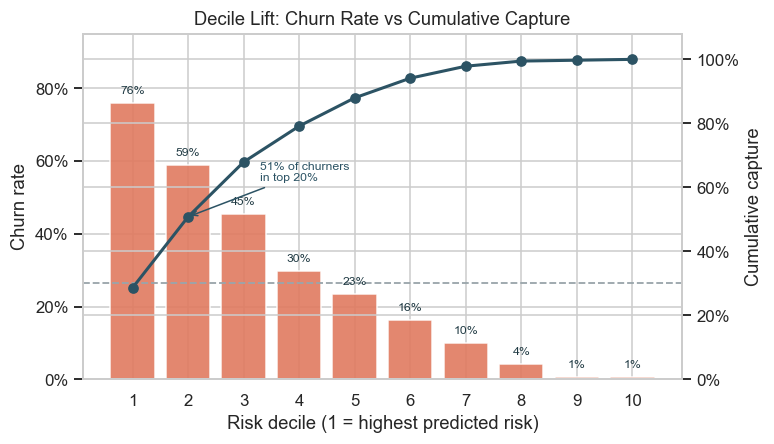

In [72]:
fig, ax1 = plt.subplots(figsize=(7.2, 4.2))
ax1.bar(decile_table["decile"], decile_table["churn_rate"], color="#e07a5f", alpha=0.9)
ax1.axhline(base_rate, color="#9aa5ab", linestyle="--", linewidth=1.2)
ax1.set_xlabel("Risk decile (1 = highest predicted risk)")
ax1.set_ylabel("Churn rate")
ax1.set_xticks(decile_table["decile"])
ax1.set_ylim(0, 0.95)
ax1.yaxis.set_major_formatter(PercentFormatter(1.0))
for x, y in zip(decile_table["decile"], decile_table["churn_rate"]):
    ax1.text(x, y + 0.02, f"{y:.0%}", ha="center", va="bottom", fontsize=8, color="#203a43")

ax2 = ax1.twinx()
ax2.plot(
    decile_table["decile"], decile_table["cumulative_capture_rate"],
    color="#2c5364", marker="o", linewidth=2,
)
ax2.set_ylabel("Cumulative capture")
ax2.set_ylim(0, 1.08)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.annotate(
    f"{decile_table.loc[decile_table['decile']==2, 'cumulative_capture_rate'].item():.0%} of churners\nin top 20%",
    xy=(2, 0.508), xytext=(3.3, 0.62),
    fontsize=8, color="#2c5364",
    arrowprops=dict(arrowstyle="->", color="#2c5364"),
)

ax1.set_title("Decile Lift: Churn Rate vs Cumulative Capture")
fig.tight_layout()
plt.show()

The staircase is monotonic: 75.9% churn in decile 1 down to 0.7% in deciles 9–10. Decile 1 is 2.86× the 26.5% test-set base rate — 107 of 141 customers there actually leave - and that single bucket already holds 28.6% of all 374 churners.

The capture line is the capacity argument. The top two deciles (20% of customers) contain 50.8% of churners (190 of 374). A random 20% list would capture about 20%. By decile 3 the model has 67.9%; after decile 6 almost nothing is left (the bottom 40% hold 6 of 374 churners).

That is the evidence for the top-20% scenario in Section 5.2. The model is not marginally better than random; it concentrates half the leavers into one-fifth of the base, and the bottom deciles are safe to ignore.

<a id="52-top-20-targeting-scenario"></a>
### 5.2 Top-20% Targeting Scenario

**What follows and why it matters.** A retention team almost never has budget to call the full base. Fix capacity at the top 20% of the risk ranking — the same cut the capture line reached 50.8% at in Section 5.1 — and ask what that budget buys: how many people are contacted, how many of those would actually have left, and how that compares with calling a random 20%.

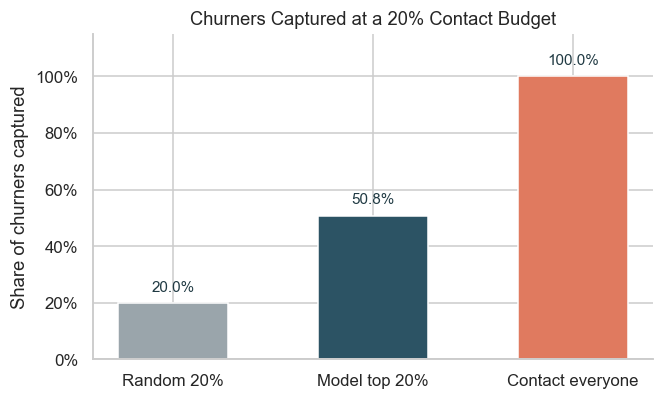

In [75]:
from IPython.display import HTML, display

top20 = top_k_capture(y_test, y_proba_test, k_pct=0.20)
n_targeted = top20["n_targeted"]
n_captured = top20["n_true_churners_captured"]
n_churners = top20["total_churners"]
capture = top20["capture_rate"]
precision = n_captured / n_targeted
random_capture = 0.20

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Customers targeted</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{n_targeted:,}</div>
    <div style="font-size:12px; color:#5b6b73;">top 20% of 1,409</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">True churners reached</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{n_captured:,} / {n_churners:,}</div>
    <div style="font-size:12px; color:#5b6b73;">{precision*100:.1f}&#37; of calls hit a leaver</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Capture vs random</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{capture*100:.1f}&#37; vs {random_capture*100:.0f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{capture / random_capture:.1f}x a random 20% list</div>
  </div>
</div>
"""))

compare = pd.DataFrame({
    "Policy": ["Random 20%", "Model top 20%", "Contact everyone"],
    "Capture": [random_capture, capture, 1.0],
})

fig, ax = plt.subplots(figsize=(6.2, 3.8))
colors = ["#9aa5ab", "#2c5364", "#e07a5f"]
bars = ax.bar(compare["Policy"], compare["Capture"], color=colors, width=0.55)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of churners captured")
ax.set_title("Churners Captured at a 20% Contact Budget")
for bar, val in zip(bars, compare["Capture"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.03, f"{val:.1%}",
            ha="center", va="bottom", fontsize=10, color="#203a43")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

A 20% budget is 282 people out of 1,409. The model puts 190 of the 374 actual churners on that list: **50.8% capture** at **67.4% precision** (two-thirds of the calls land on someone who would have left).

The gray bar is the honest baseline. A random 20% list captures about 20%. The navy bar is 2.5× that, at the same headcount. The orange bar is 100% capture - and 5× the effort.

So the ranked list is the efficient middle: half the leavers, one-fifth of the base. That is the list Section 5.4 prices. The remaining 184 churners sit further down the ranking; reaching them means buying more call capacity, not a different model.

<a id="53-revenue-at-risk"></a>
### 5.3 Revenue at Risk

**What follows and why it matters.** Section 5.2 ranked people for a *capacity-limited* call list. This cell asks a different question: if we apply the F1-optimal threshold from Section 4.3 (`best_threshold` = 0.59), how much annual billing sits behind everyone the model flags? That is the exposure a retention budget is sized against — not a forecast of money already lost.

In [78]:
from IPython.display import HTML, display

HORIZON_MONTHS = 12
rar = revenue_at_risk(
    X_test["MonthlyCharges"], y_proba_test, best_threshold, horizon_months=HORIZON_MONTHS
)
n_flagged = rar["n_flagged"]
avg_bill = rar["avg_monthly_charge"]
exposure = rar["total_revenue_at_risk"]
flag_share = n_flagged / len(X_test)

display(HTML(f"""
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Flagged at threshold {best_threshold:.2f}</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{n_flagged:,}</div>
    <div style="font-size:12px; color:#5b6b73;">{flag_share:.1%} of the 1,409 test set</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Avg monthly charge (flagged)</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">${avg_bill:,.2f}</div>
    <div style="font-size:12px; color:#5b6b73;">× {HORIZON_MONTHS} months if they stay</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">{HORIZON_MONTHS}-month revenue at risk</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">${exposure:,.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">exposure, not expected loss</div>
  </div>
</div>
"""))

Formula: sum of `MonthlyCharges` for everyone with predicted probability ≥ 0.59, times 12. That is **491 accounts** (34.8% of the test set), **$74.89** per month on average, and **$441,250** of 12-month billing behind the flagged group.

This is *exposure*, not a loss forecast. It assumes the current bill continues for a year and treats every flagged customer as a leaver — neither is true. It answers “how much revenue sits on the accounts we are marking at risk?” which is the number that justifies a retention budget.

Keep it separate from Section 5.2. The threshold flags 491 people; the call list is 282. A deployment uses 0.59 to decide *who is at risk* and the ranking to decide *who gets called this month*. Section 5.4 prices the cheaper 282-person campaign, not this full $441k pool.

<a id="54-campaign-roi"></a>
### 5.4 Campaign ROI

**What follows and why it matters.** A flag only creates value if outreach costs less than the revenue you keep. This cell prices one concrete campaign on the Section 5.2 list (282 contacts, 190 true churners). Two assumptions are left in the open so a stakeholder can change them: **$50** per contact, and a **35%** success rate among contacted customers who would actually have left. Cost is paid on every call; revenue is credited only for those true churners who stay.

In [81]:
from IPython.display import HTML, display

HORIZON_MONTHS = 12
RETENTION_COST_PER_CUSTOMER = 50.0
RETENTION_SUCCESS_RATE = 0.35

top20 = top_k_capture(y_test, y_proba_test, k_pct=0.20)

roi = campaign_roi(
    n_true_churners_captured=top20["n_true_churners_captured"],
    avg_monthly_charge=X_test["MonthlyCharges"].mean(),
    retention_cost_per_customer=RETENTION_COST_PER_CUSTOMER,
    retention_success_rate=RETENTION_SUCCESS_RATE,
    n_targeted=top20["n_targeted"],
    horizon_months=HORIZON_MONTHS,
)

n_retained = roi["customers_retained_est"]
avg_bill = float(X_test["MonthlyCharges"].mean())
break_even = roi["campaign_cost"] / (
    top20["n_true_churners_captured"] * avg_bill * HORIZON_MONTHS
)

display(HTML(f"""
<div style="font-size:13px; color:#5b6b73; margin-bottom:10px; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  Assumptions: ${RETENTION_COST_PER_CUSTOMER:.0f} per contact · {RETENTION_SUCCESS_RATE:.0%} save rate on true churners ·
  ${avg_bill:.2f} avg monthly bill (full test set) · {HORIZON_MONTHS}-month horizon
</div>
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Campaign cost</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">${roi['campaign_cost']:,.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">{top20['n_targeted']} × ${RETENTION_COST_PER_CUSTOMER:.0f}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Revenue saved</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">${roi['revenue_saved']:,.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">{n_retained:.0f} retained × ${avg_bill:.0f} × {HORIZON_MONTHS}</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #e07a5f;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Net benefit</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">${roi['net_benefit']:,.0f}</div>
    <div style="font-size:12px; color:#5b6b73;">saved − cost</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9c27b0;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Net ROI</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{roi['roi_multiple']:.1f}x</div>
    <div style="font-size:12px; color:#5b6b73;">break-even save rate {break_even:.0%}</div>
  </div>
</div>
"""))

| Card | Value | What it means |
|------|------:|---------------|
| Campaign cost | **\$14,100** | Paid on every name: 282 x \$50, including people who would have stayed. |
| Revenue saved | **\$51,143** | Credit only about 66 retained leavers (190 x 35%), each at about \$64 x 12. |
| Net benefit | **\$37,043** | Saved minus cost. Campaign surplus on this test set. |
| Net ROI | **3.6x** | \$51,143 / \$14,100. Break-even save rate is about 10%; 35% is well above that. |

This prices the Section 5.2 list, not the 491-person threshold pool. **282** contacts at **\$50** each is **\$14,100** — paid on every name. Revenue is credited only for true churners who are saved: 190 x 35% ≈ **66** accounts, billed at the **full test-set** average (**\$64.09**, not the flagged \$74.89), for 12 months → **\$51,143** saved.

The 35% save rate is an assumption, not something this test set measured. The ranking and the 190 captured churners *are* measured. Two conservative choices keep the multiple from looking better than it is: the cheaper test-set mean bill, and no revenue credit for false positives who still cost \$50. A cheaper channel or a real pilot with a higher save rate would raise 3.6x; a weaker offer would cut it. Change `50` or `0.35` in the cell above and the cards update. This is not the \$441,250 exposure from Section 5.3 — that was the pool at risk; this is one 282-person campaign against that pool.

<a id="55-what-if-simulator"></a>
### 5.5 What-If Simulator

**What follows and why it matters.** The SHAP waterfall said *why* a high-risk month-to-month customer scored 95%. This cell tests two concrete offers on that same kind of account: a one-year contract, then the same contract plus Tech Support and Online Security. The model is not refit. Each bar is a rescore of one real test-set row after those fields are overwritten. A drop in predicted probability is a modeled score movement, not a guarantee the customer stays — and the simulator does not raise `MonthlyCharges`, so it is an upper bound, not a priced offer.

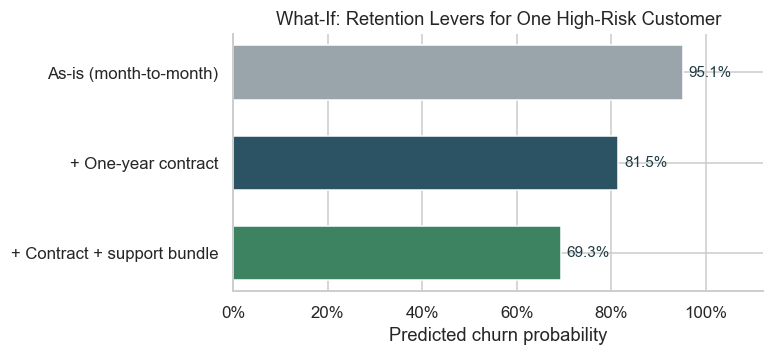

In [84]:
from IPython.display import HTML, display

month_to_month_mask = (X_test["Contract"] == "Month-to-month").values
candidate_idx = np.where(month_to_month_mask)[0][np.argmax(y_proba_test[month_to_month_mask])]
sample_customer = X_test.iloc[[candidate_idx]]
row = sample_customer.iloc[0]

scenario_contract = what_if_simulator(champion_pipeline, sample_customer, {"Contract": "One year"})
scenario_support = what_if_simulator(
    champion_pipeline, sample_customer,
    {"Contract": "One year", "TechSupport": 1, "OnlineSecurity": 1},
)

p0 = scenario_contract["baseline_probability"]
p1 = scenario_contract["simulated_probability"]
p2 = scenario_support["simulated_probability"]

scenarios = pd.DataFrame([
    {"Scenario": "As-is (month-to-month)", "Predicted Probability": p0},
    {"Scenario": "+ One-year contract", "Predicted Probability": p1},
    {"Scenario": "+ Contract + support bundle", "Predicted Probability": p2},
])

display(HTML(f"""
<div style="font-size:13px; color:#5b6b73; margin-bottom:10px; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  Profile: {row['Contract']} · {row['InternetService']} · tenure {int(row['tenure'])} mo ·
  &#36;{row['MonthlyCharges']:.2f}/mo · TechSupport {int(row['TechSupport'])} ·
  OnlineSecurity {int(row['OnlineSecurity'])}
</div>
<div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif;">
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #9aa5ab;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Baseline</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{p0*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">as-is predicted churn</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">+ One-year contract</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{p1*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{(p1-p0)*100:+.1f} pp vs baseline</div>
  </div>
  <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #3d8361;">
    <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">+ Contract + support</div>
    <div style="font-size:22px; font-weight:600; color:#203a43;">{p2*100:.1f}&#37;</div>
    <div style="font-size:12px; color:#5b6b73;">{(p2-p0)*100:+.1f} pp vs baseline</div>
  </div>
</div>
"""))

fig, ax = plt.subplots(figsize=(7.2, 3.4))
colors = ["#9aa5ab", "#2c5364", "#3d8361"]
y = scenarios["Scenario"]
x = scenarios["Predicted Probability"]
bars = ax.barh(y, x, color=colors, height=0.6)
ax.invert_yaxis()
ax.set_xlim(0, x.max() * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Predicted churn probability")
ax.set_title("What-If: Retention Levers for One High-Risk Customer")
for bar, val in zip(bars, x):
    ax.text(val + 0.012, bar.get_y() + bar.get_height() / 2, f"{val:.1%}",
            va="center", ha="left", fontsize=10, color="#203a43")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

| Offer | Predicted churn | Change vs as-is |
|-------|----------------:|----------------:|
| As-is (month-to-month) | **95.1%** | — |
| + One-year contract | **81.5%** | **−13.6 pp** |
| + Contract + support bundle | **69.3%** | **−25.8 pp** |

This is the same kind of account as the Section 4 waterfall: month-to-month, fiber, **1 month** of tenure, **\$95.10** per month, no Tech Support, no Online Security. Baseline predicted churn is **95.1%**.

A one-year contract alone moves the score to **81.5%**. Adding Tech Support and Online Security takes it to **69.3%**. Contract does most of the work (−13.6 pp); the support bundle adds another ~12 pp on top. That matches SHAP - contract was a top driver - but it is a *score* movement, not a guarantee this person stays.

Two limits keep this from being an offer you can ship as-is. The simulator does not raise `MonthlyCharges`, so a real support bundle would likely cost more and the drop is an **upper bound**. And **69.3% is still well above** the 0.59 flag from Section 4.3: tenure, fiber, and the bill-to-history ratio are still in the score. Section 6 puts this same customer on live controls so you can try those other levers - two-year term, bill, tenure - without rewriting the cell.

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="6-live-dashboard"></a>
## 6. Live Dashboard

**What follows and why it matters.** Section 5.5 tested two fixed offers on one high-risk row. This cell puts that same customer on live controls and rescores with the **same** `champion_pipeline` — no refit, no mock-up. The black line on the meter is the Section 4.3 threshold (0.59). High / Low is that flag, not a promise they leave.

Each click overwrites contract, internet, tenure, monthly bill, Tech Support, and Online Security, then rebuilds `TenureBucket`, `TotalServicesSubscribed`, `TotalCharges` (monthly × tenure), and `ChargeRatio` so those engineered fields stay consistent with the sliders. Other columns (payment method, remaining add-ons) stay as they were on this account.

In [88]:
import ipywidgets as widgets
from IPython.display import HTML, display, clear_output

if "candidate_idx" not in dir():
    _mtm = (X_test["Contract"] == "Month-to-month").values
    candidate_idx = np.where(_mtm)[0][np.argmax(y_proba_test[_mtm])]

template_customer = X_test.iloc[[candidate_idx]].copy()
baseline_proba = float(champion_pipeline.predict_proba(template_customer)[:, 1][0])

style = {"description_width": "110px"}
slider_layout = widgets.Layout(width="340px")

contract_dd = widgets.Dropdown(
    options=["Month-to-month", "One year", "Two year"],
    value=template_customer["Contract"].iloc[0], description="Contract:", style=style,
)
internet_dd = widgets.Dropdown(
    options=["DSL", "Fiber optic", "No"],
    value=template_customer["InternetService"].iloc[0], description="Internet:", style=style,
)
tenure_slider = widgets.IntSlider(
    value=int(template_customer["tenure"].iloc[0]), min=0, max=72, step=1,
    description="Tenure (mo):", style=style, layout=slider_layout,
)
charges_slider = widgets.FloatSlider(
    value=float(template_customer["MonthlyCharges"].iloc[0]), min=18.0, max=120.0, step=1.0,
    description="Monthly bill:", style=style, layout=slider_layout,
)
techsupport_cb = widgets.Checkbox(
    value=bool(template_customer["TechSupport"].iloc[0]), description="Tech Support",
)
security_cb = widgets.Checkbox(
    value=bool(template_customer["OnlineSecurity"].iloc[0]), description="Online Security",
)
score_button = widgets.Button(description="Score customer", button_style="primary")
output_area = widgets.Output()

def score_customer(_):
    with output_area:
        clear_output(wait=True)
        modified = template_customer.copy()
        tenure_val = int(tenure_slider.value)
        charges_val = float(charges_slider.value)
        modified["Contract"] = contract_dd.value
        modified["InternetService"] = internet_dd.value
        modified["tenure"] = tenure_val
        modified["MonthlyCharges"] = charges_val
        modified["TechSupport"] = int(techsupport_cb.value)
        modified["OnlineSecurity"] = int(security_cb.value)
        service_cols = [
            "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies",
        ]
        modified["TotalServicesSubscribed"] = modified[service_cols].sum(axis=1)
        modified["TotalCharges"] = charges_val * tenure_val
        modified["ChargeRatio"] = charges_val / (modified["TotalCharges"].iloc[0] + 1)
        modified["TenureBucket"] = pd.cut(
            modified["tenure"].astype(float),
            bins=[-1, 12, 24, 48, 72],
            labels=["0-1-year", "1-2-years", "2-4-years", "4+-years"],
        )

        proba = float(champion_pipeline.predict_proba(modified)[:, 1][0])
        flagged = proba >= best_threshold
        risk_label = "High" if flagged else "Low"
        risk_color = "#e07a5f" if flagged else "#3d8361"
        delta_pp = (proba - baseline_proba) * 100

        display(HTML(f"""
        <div style="display:flex; gap:16px; flex-wrap:wrap; font-family:'Segoe UI', Helvetica, Arial, sans-serif; margin-bottom:8px;">
          <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid {risk_color};">
            <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Predicted churn</div>
            <div style="font-size:22px; font-weight:600; color:#203a43;">{proba*100:.1f}&#37;</div>
            <div style="font-size:12px; color:#5b6b73;">{delta_pp:+.1f} pp vs this account as-is</div>
          </div>
          <div style="flex:1; min-width:160px; background:#f4f6f7; border-radius:10px; padding:16px 18px; border-left:5px solid #2c5364;">
            <div style="font-size:12px; text-transform:uppercase; color:#5b6b73;">Flag at {best_threshold:.2f}</div>
            <div style="font-size:22px; font-weight:600; color:#203a43;">{risk_label}</div>
            <div style="font-size:12px; color:#5b6b73;">same cutoff as Section 4.3</div>
          </div>
        </div>
        """))

        fig, ax = plt.subplots(figsize=(7.2, 1.6))
        ax.barh(["Predicted churn"], [proba], color=risk_color, height=0.45)
        ax.axvline(best_threshold, color="#203a43", linestyle="--", linewidth=1.4)
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.set_title("Live score vs 0.59 decision threshold")
        ax.text(min(proba + 0.02, 0.88), 0, f"{proba:.1%}", va="center", fontsize=10, color="#203a43")
        ax.spines[["top", "right"]].set_visible(False)
        plt.tight_layout()
        plt.show()

score_button.on_click(score_customer)

display(widgets.VBox([
    widgets.HTML("<b>Same Section 5.5 customer. Change a lever, then Score.</b>"),
    widgets.HBox([contract_dd, internet_dd]),
    widgets.HBox([tenure_slider, charges_slider]),
    widgets.HBox([techsupport_cb, security_cb, score_button]),
    output_area,
]))
score_customer(None)

| Widget | This account as-is |
|--------|-------------------|
| Contract / internet | Month-to-month · Fiber optic |
| Tenure / monthly bill | 1 month · \$95 |
| Tech Support / Online Security | Off / Off |
| Score | **95.1%** predicted churn · **High** vs the 0.59 flag |

This is the same 1-month fiber row from Sections 4 and 5.5. **+0.0 pp vs as-is** means the sliders have not moved the record yet; the orange bar is the raw champion score. The dashed line is the Section 4.3 cutoff: anything at or above **0.59** is the High flag used to size exposure in 5.3. This customer is far past it.

Click **Score customer** after each change — the widgets do not rescore on drag. Replaying Section 5.5 (one-year contract, then both checkboxes) should land near **81.5%** then **69.3%**, still High. Tenure, two-year, and internet are the extra levers that cell did not test. `TotalCharges` is rebuilt as monthly bill × tenure so `ChargeRatio` and `TenureBucket` stay consistent with the sliders; payment method and the other add-ons stay as they were on this row.

A lower score is still a *model* movement, not a promise they stay. Section 7 pulls the ranking, the dollars, and these limits into one set of claims a stakeholder can take or challenge.

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>

<a id="7-conclusions"></a>
## 7. Conclusions

The useful output of this project is not a leaderboard score. It is a **ranked call list** that, on 1,409 held-out customers, puts **190 of 374** actual leavers into **282** contacts: **50.8% capture** at **67.4% precision** - **2.5×** a random 20% list at the same headcount.

| Decision | Number | What it is |
|----------|-------:|------------|
| Ranked list (top 20%) | **282** people · **190** true churners | Who to call this month |
| Flag at 0.59 | **491** people · **\$441,250** | 12-month billing *sitting behind* the flag - exposure, not a loss forecast |
| Costed campaign on the 282 | **\$14,100** cost · **\$51,143** saved · **\$37,043** net · **3.6×** | \$50 per contact and a 35% save rate; break-even is about **10%** |

The 50.8% capture is measured on the test set. The 3.6× is not: it uses a **\$50** outreach cost and a **35%** save rate that a real pilot has to replace. Two conservative choices keep that multiple from looking better than it is - the cheaper full-test-set bill (**\$64.09**, not the flagged **\$74.89**), and no revenue credit for false positives who still cost \$50.

**What to pull.** Contract is the first lever (month-to-month vs term; the contract dummies are ~29% of top-15 SHAP mass). Then bill-to-history pressure (`ChargeRatio`), fiber, and monthly charge. That is not uniform: already-on-term customers are largely protected by the term itself; month-to-month customers still churn on charge and service. For the worst test-set account (1-month fiber, \$95.10, no support), a one-year contract moves predicted churn **95.1% → 81.5%**; adding Tech Support and Online Security reaches **69.3%**. Still **High** vs 0.59. Contract is necessary. It is not sufficient for that row.

**What this is not.** SHAP and the what-if cell explain and move *the model*. They do not prove a causal treatment effect. The data are one snapshot: who is at risk *now*, not whether risk is rising. All metrics are one 80/20 split at `random_state=42`.

**Do this next, in order.**

1. **Pilot the 282-person list against a holdout** so the 35% save rate becomes a measured one. Until that number exists, treat 3.6× as a scenario, not a budget.
2. **Staff to the list, not the flag.** 0.59 marks exposure (491). Capacity should follow the ranking (282, then deeper only if the pilot saves people).
3. **Promote `champion_pipeline` into `app/`** using the Section 6 controls as the UI, with no change to `src/`. Revisit 0.59 only after you know how many accounts retention can actually touch per month.

<a id="8-references"></a>
## 8. References

**Dataset**
- IBM. *Telco Customer Churn.* Publicly distributed sample dataset, 7,043 customers / 21 features. Included locally at `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`.

**Methods &amp; Libraries**
- Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide.*
- Lundberg, S. M. &amp; Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS. (SHAP)
- Akiba, T. et al. (2019). *Optuna: A Next-generation Hyperparameter Optimization Framework.* KDD.
- Chen, T. &amp; Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System.* KDD.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR.
- Niculescu-Mizil, A. &amp; Caruana, R. (2005). *Predicting Good Probabilities with Supervised Learning.* ICML. (Calibration)

**Project**
- Source code, README, and this notebook: `customer-churn-prediction/` (see `src/data_pipeline.py`, `src/modeling.py`, `src/interpretability.py`, `src/business_impact.py`).

- Author: Sileshi Hirpa - [hirpast@gmail.com](mailto:hirpast@gmail.com) | [linkedin.com/in/sileshi-hirpa](https://www.linkedin.com/in/sileshi-hirpa) | [github.com/sileshith](https://github.com/sileshith) | [hirpadata.com](https://hirpadata.com/)

<div align="right"><a href="#table-of-contents" style="font-size:13px;">&#8593; Back to top</a></div>